# Prediksi Harga Rumah | Early Bird Data Science

Nama: Ryandika Syauqi Ramadhani

NIM : A11.2023.15349

Alur pengerjaan: EDA, direct modeling, preprocessing, feature selection, tuning, evaluasi, dan penyimpanan model untuk Streamlit.

Dataset masih berupa hasil scraping, jadi beberapa isi kolom perlu diperiksa sebelum dipakai. Jalankan notebook dari atas ke bawah. Jika file `Raw-Final-Rumah.csv` belum tersedia, unggah dataset saat diminta.

## 0. Import library
Library standar: pandas, numpy, matplotlib, seaborn, scikit-learn, joblib. RANDOM_STATE dipakai di semua proses acak supaya hasil bisa diulang.

In [ ]:
import os
import re
import time
import warnings
from importlib.metadata import version

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (wajib sebelum import IterativeImputer)
from sklearn.feature_selection import mutual_info_regression
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.linear_model import BayesianRidge, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

from sklearn.exceptions import ConvergenceWarning

RANDOM_STATE = 42

warnings.filterwarnings('ignore', category=ConvergenceWarning)
sns.set_style('whitegrid')
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
pd.set_option('display.max_columns', 30)
print('scikit-learn', sklearn.__version__)

scikit-learn 1.6.1


## 1. EDA
### 1.1 Load data
Semua kolom bertipe teks kecuali `Page`, jadi perlu diparsing.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
file_path = '/content/drive/MyDrive/Dataset/Raw-Final-Rumah.csv'
df = pd.read_csv(file_path)

print('Ukuran data:', df.shape)
df.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ukuran data: (40200, 8)


,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
0,"2,5 Miliar",4,3,10,LT : 438 m²,LB : 110 m²,Tapos,129
1,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Pancoran Mas,129
2,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Cipayung,129
3,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Rangkapanjaya,129
4,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Pancoran Mas,129


Tipe data dan jumlah missing per kolom.

In [ ]:
df.info()
print()
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40200 entries, 0 to 40199
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Harga          40200 non-null  object
 1   Kamar Tidur    40191 non-null  object
 2   Kamar Mandi    35797 non-null  object
 3   Garasi         35011 non-null  object
 4   Luas Tanah     32501 non-null  object
 5   Luas Bangunan  24598 non-null  object
 6   Kecamatan      40200 non-null  object
 7   Page           40200 non-null  int64 
dtypes: int64(1), object(7)
memory usage: 2.5+ MB

Harga                0
Kamar Tidur          9
Kamar Mandi       4403
Garasi            5189
Luas Tanah        7699
Luas Bangunan    15602
Kecamatan            0
Page                 0
dtype: int64


### 1.2 Pola isi tiap kolom
Angka diganti `N` supaya variasi format terlihat. Kolom `Kamar Tidur`, `Kamar Mandi`, `Garasi` sering berisi `LT : ... m²` atau `LB : ... m²`, dan `Luas Tanah` kadang berisi `LB`. Jadi **isi kolom bergeser ke kiri** kalau ada field kosong di sumber (hasil scraping).

In [ ]:
# angka diganti N supaya variasi format tiap kolom kelihatan
def pola(s):
    return s.fillna('KOSONG').astype(str).str.replace(r'\d+', 'N', regex=True)

for kolom in ['Kamar Tidur', 'Kamar Mandi', 'Garasi', 'Luas Tanah', 'Luas Bangunan']:
    print('==', kolom)
    print(pola(df[kolom]).value_counts().head(6))
    print()

== Kamar Tidur
Kamar Tidur
N          35250
LT:N m²     4851
LB:N m²       90
KOSONG         9
Name: count, dtype: int64

== Kamar Mandi
Kamar Mandi
N          33636
KOSONG      4403
LT:N m²     1379
LB:N m²      782
Name: count, dtype: int64

== Garasi
Garasi
N          24607
LT:N m²     7906
KOSONG      5189
LB:N m²     2498
Name: count, dtype: int64

== Luas Tanah
Luas Tanah
LT : N m²    24600
LB : N m²     7901
KOSONG        7699
Name: count, dtype: int64

== Luas Bangunan
Luas Bangunan
LB : N m²    24598
KOSONG       15602
Name: count, dtype: int64



Format harga: `Miliar`, `Juta`, akhiran `Total`, dan yang janggal: `Triliun`, `Ribu`, `/m²`, `/ha`, `Hubungi Agen`.

In [ ]:
print(pola(df['Harga']).value_counts())
print()
print(df[df['Harga'].str.contains('Triliun|Ribu')].head(8))

Harga
N,N Miliar           17462
N Juta               13793
N,N Miliar Total      3731
N Miliar              2800
N Miliar Total        1352
N Juta Total           683
N,N Juta Total         124
N,N Juta                79
N,N Triliun Total       51
Hubungi Agen            41
N Juta /m²              22
N,N Juta /m²            22
N Ribu                  11
N,N Miliar /m²           9
N Triliun Total          8
N,N Triliun              7
N Miliar /m²             2
N,N Ribu                 1
N Ribu Total             1
N,N Juta /ha             1
Name: count, dtype: int64

                   Harga Kamar Tidur  Kamar Mandi       Garasi Luas Tanah  \
127   19,8 Triliun Total  LT:2100 m²          NaN          NaN        NaN   
1908  15,5 Triliun Total  LT:1070 m²          NaN          NaN        NaN   
3181         1,4 Triliun          91  LT:92000 m²  LB:14000 m²        NaN   
3680   2,3 Triliun Total   LT:689 m²          NaN          NaN        NaN   
4463  20,5 Triliun Total  LT:2134 m²      

### 1.3 Duplikat dan kolom Page
Duplikat dicek dengan 3 cara. Banyak baris sama persis kecuali `Page` atau `Kecamatan`. `Page` isinya tepat 20 baris per halaman, jadi hanya artefak scraping dan tidak dipakai untuk model.

In [ ]:
kolom_tanpa_page = [c for c in df.columns if c != 'Page']
kolom_tanpa_page_kec = [c for c in df.columns if c not in ['Page', 'Kecamatan']]

print('duplikat identik            :', df.duplicated().sum())
print('duplikat (abaikan Page)     :', df.duplicated(subset=kolom_tanpa_page).sum())
print('duplikat (abaikan Page+Kec) :', df.duplicated(subset=kolom_tanpa_page_kec).sum())

# satu listing muncul di berapa kecamatan?
jml_kec = df.groupby(kolom_tanpa_page_kec, dropna=False)['Kecamatan'].nunique()
print('grup listing yang muncul di >1 kecamatan:', (jml_kec > 1).sum())

print(df.groupby('Page').size().describe())

duplikat identik            : 1525
duplikat (abaikan Page)     : 9478
duplikat (abaikan Page+Kec) : 12331
grup listing yang muncul di >1 kecamatan: 2041
count   2,010.00
mean       20.00
std         0.00
min        20.00
25%        20.00
50%        20.00
75%        20.00
max        20.00
dtype: float64


Beberapa pasangan label tampak seperti kecamatan dan kelurahan, misalnya Cinere | Pangkalan Jati atau Beji | Kukusan. Ini bisa menunjukkan listing yang sama dengan label wilayah berbeda, tetapi belum pasti karena dataset tidak punya URL atau ID listing.

In [ ]:
# pasangan label kecamatan yang paling sering muncul untuk listing yang sama
grup_multi = jml_kec[jml_kec > 1].reset_index()[kolom_tanpa_page_kec]
sub = df.merge(grup_multi, on=kolom_tanpa_page_kec)
pasangan = sub.groupby(kolom_tanpa_page_kec, dropna=False)['Kecamatan'].apply(lambda s: ' | '.join(sorted(set(s))))
pasangan.value_counts().head(8)

,count
Kecamatan,
Cinere | Limo,83
Bojong Sari | Sawangan,75
Beji | Kukusan,47
Cinere | Pangkalan Jati,45
Cimanggis | Tapos,39
Cinangka | Sawangan,36
Beji | Margonda,35
Pancoran Mas | Sawangan,35


### 1.4 Parsing
- `parse_harga`: harga total dalam Miliar/Juta dikali ke rupiah. `Triliun`, `Ribu`, harga per m²/ha, dan `Hubungi Agen` diaudit sebagai format yang belum aman dipakai sebagai harga total.
- `parse_kamar`: KT, KM, dan Garasi dibaca dari kolom aslinya hanya jika berupa angka.
- `parse_luas`: LT dan LB dicari lintas kolom berdasarkan label. Jika satu baris memiliki beberapa kandidat yang berbeda, nilai ditandai missing untuk diperiksa, bukan dipilih diam-diam.


In [ ]:
kolom_fitur = ['Kamar Tidur', 'Kamar Mandi', 'Garasi', 'Luas Tanah', 'Luas Bangunan']

def angka_indonesia(teks):
    """Ubah angka dengan format Indonesia ke float. Pemisah ambigu perlu diaudit."""
    teks = str(teks).strip().replace(' ', '')
    if not teks:
        return np.nan
    if ',' in teks and '.' in teks:
        # Format Indonesia yang umum: titik ribuan, koma desimal.
        if teks.rfind(',') > teks.rfind('.'):
            teks = teks.replace('.', '').replace(',', '.')
        else:
            teks = teks.replace(',', '')
    elif ',' in teks:
        # 1,200 dapat berarti 1200 pada data dengan pemisah ribuan.
        if re.fullmatch(r'\d{1,3}(,\d{3})+', teks):
            teks = teks.replace(',', '')
        else:
            teks = teks.replace(',', '.')
    elif '.' in teks:
        # Titik dengan tiga digit berulang diperlakukan sebagai pemisah ribuan.
        if re.fullmatch(r'\d{1,3}(\.\d{3})+', teks):
            teks = teks.replace('.', '')
    try:
        return float(teks)
    except ValueError:
        return np.nan

def parse_harga(teks):
    """Harga total dalam rupiah. Format per luas/harga tak dicantumkan tidak dipakai."""
    teks = str(teks).strip()
    if re.search(r'Hubungi|/\s*m(?:²|2)?|/\s*ha|Triliun|Ribu', teks, flags=re.I):
        return np.nan
    m = re.search(r'(\d[\d.,]*)\s*(Miliar|Juta)\b', teks, flags=re.I)
    if m is None:
        return np.nan
    angka = angka_indonesia(m.group(1))
    if not np.isfinite(angka):
        return np.nan
    pengali = 1e9 if m.group(2).lower() == 'miliar' else 1e6
    return angka * pengali

def parse_kamar(nilai):
    """KT/KM/Garasi dibaca dari kolom aslinya hanya kalau berupa angka bulat."""
    if pd.notna(nilai) and re.fullmatch(r'\d+', str(nilai).strip()):
        return float(nilai)
    return np.nan

def kandidat_luas(baris, label):
    """Ambil semua kandidat LT/LB dengan label eksplisit dari seluruh kolom."""
    hasil = []
    for nilai in baris:
        if pd.isna(nilai):
            continue
        pola = rf'\b{label}\s*:\s*(\d[\d.,]*)'
        for m in re.finditer(pola, str(nilai), flags=re.I):
            angka = angka_indonesia(m.group(1))
            if np.isfinite(angka):
                hasil.append(angka)
    # Nilai sama yang muncul di dua kolom tidak dianggap konflik.
    return sorted(set(hasil))

def parse_luas(baris, label):
    """Ambil LT/LB hanya jika kandidat yang ditemukan tidak saling bertentangan."""
    kandidat = kandidat_luas(baris, label)
    return kandidat[0] if len(kandidat) == 1 else np.nan

d = pd.DataFrame(index=df.index)
d['Harga'] = df['Harga'].map(parse_harga)
d['KT'] = df['Kamar Tidur'].map(parse_kamar)
d['KM'] = df['Kamar Mandi'].map(parse_kamar)
d['Garasi'] = df['Garasi'].map(parse_kamar)
d['LT'] = df[kolom_fitur].apply(parse_luas, axis=1, label='LT')
d['LB'] = df[kolom_fitur].apply(parse_luas, axis=1, label='LB')
d['Kecamatan'] = df['Kecamatan'].astype('string').fillna('Unknown').str.strip()

# Baris dengan lebih dari satu nilai LT/LB yang berbeda ditandai, bukan ditebak.
kandidat_lt = df[kolom_fitur].apply(kandidat_luas, axis=1, label='LT')
kandidat_lb = df[kolom_fitur].apply(kandidat_luas, axis=1, label='LB')
konflik_lt = kandidat_lt.map(len) > 1
konflik_lb = kandidat_lb.map(len) > 1
print('Kandidat LT bertentangan:', int(konflik_lt.sum()))
print('Kandidat LB bertentangan:', int(konflik_lb.sum()))
if konflik_lt.any() or konflik_lb.any():
    idx_konflik = df.index[konflik_lt | konflik_lb]
    display(df.loc[idx_konflik, kolom_fitur].head(10))

print('Missing setelah parsing:')
print(d.isna().sum())
d.describe(percentiles=[.01, .5, .99]).T


Kandidat LT bertentangan: 0
Kandidat LB bertentangan: 0
Missing setelah parsing:
Harga          176
KT            4950
KM            6564
Garasi       15593
LT            1464
LB            4331
Kecamatan        0
dtype: int64


,count,mean,std,min,1%,50%,99%,max
Harga,"40,024.00","5,089,691,871.38","29,598,409,337.16","1,030,000.00","85,000,000.00","1,500,000,000.00","50,000,000,000.00","999,000,000,000.00"
KT,"35,250.00",3.67,4.72,1.00,1.00,3.00,21.00,284.00
KM,"33,636.00",2.75,3.68,1.00,1.00,2.00,17.00,180.00
Garasi,"24,607.00",1.59,1.40,1.00,1.00,1.00,7.00,30.00
LT,"38,736.00","37,141.44","4,519,609.69",1.00,40.00,115.00,"9,000.00","818,801,098.00"
LB,"35,869.00","25,863.80","4,355,443.46",1.00,22.00,100.00,"1,428.00","818,801,098.00"


Audit harga yang gagal diparse: dikelompokkan dan ditampilkan contohnya. `Triliun` tidak masuk akal untuk rumah (contoh 1.525 Triliun), `Ribu` terlihat seperti harga per m²/sewa, `/m²` dan `/ha` adalah listing tanah.

In [ ]:
# audit: harga yang tidak bisa diparse dikelompokkan, dan ditampilkan contoh mentahnya
def kategori_gagal(teks):
    for nama, pola_re in [('Triliun', 'Triliun'), ('Ribu', 'Ribu'), ('per m2 / per ha', '/m|/ha'), ('Hubungi Agen', 'Hubungi')]:
        if re.search(pola_re, teks, flags=re.I):
            return nama
    return 'format lain'

gagal = df.loc[d['Harga'].isna(), 'Harga']
audit = pd.DataFrame({'kategori': gagal.map(kategori_gagal), 'contoh': gagal})
print('harga berhasil diparse:', d['Harga'].notna().sum(), '| gagal:', len(gagal))
print(audit['kategori'].value_counts())
print()
for kat, grup in audit.groupby('kategori'):
    print(kat, '->', grup['contoh'].head(4).tolist())

harga berhasil diparse: 40024 | gagal: 176
kategori
Triliun            66
per m2 / per ha    56
Hubungi Agen       41
Ribu               13
Name: count, dtype: int64

Hubungi Agen -> ['Hubungi Agen', 'Hubungi Agen', 'Hubungi Agen', 'Hubungi Agen']
Ribu -> ['900 Ribu', '422 Ribu', '414 Ribu', '893 Ribu']
Triliun -> ['19,8 Triliun Total', '15,5 Triliun Total', '1,4 Triliun', '2,3 Triliun Total']
per m2 / per ha -> ['5,35 Juta /m²', '17 Juta /m²', '3 Miliar /m²', '5,3 Juta /m²']


### 1.5 Tabel temuan kualitas data
Kolom terakhir sengaja diberi label *dugaan*: jumlah baris adalah fakta terukur, penyebabnya hipotesis.

In [ ]:
h = df['Harga']
tabel = pd.DataFrame([
    ['Harga satuan Triliun', h.str.contains('Triliun').sum(), 'Nominal tidak masuk akal untuk rumah (contoh 1.525 Triliun), kemungkinan salah input'],
    ['Harga satuan Ribu', h.str.contains('Ribu').sum(), 'Kemungkinan harga per m2 / sewa, bukan harga rumah'],
    ['Harga per m2 / per ha', h.str.contains('/m|/ha').sum(), 'Listing tanah, harga bukan total'],
    ['Harga "Hubungi Agen"', h.str.contains('Hubungi').sum(), 'Harga tidak dicantumkan'],
    ['Harga ada akhiran "Total"', h.str.contains('Total').sum(), 'Keterangan tambahan saja'],
    ['Kolom Kamar Tidur berisi LT/LB', df['Kamar Tidur'].astype(str).str.startswith(('LT', 'LB')).sum(), 'Field kosong di sumber, nilai geser ke kiri'],
    ['Kolom Kamar Mandi berisi LT/LB', df['Kamar Mandi'].astype(str).str.startswith(('LT', 'LB')).sum(), 'Idem'],
    ['Kolom Garasi berisi LT/LB', df['Garasi'].astype(str).str.startswith(('LT', 'LB')).sum(), 'Idem'],
    ['Kolom Luas Tanah berisi LB', df['Luas Tanah'].astype(str).str.startswith('LB').sum(), 'Idem'],
    ['Missing Luas Bangunan (mentah)', df['Luas Bangunan'].isna().sum(), 'Sebagian karena geser, sebagian memang tidak ada'],
    ['Missing Luas Tanah (mentah)', df['Luas Tanah'].isna().sum(), 'Idem'],
    ['Missing Garasi (mentah)', df['Garasi'].isna().sum(), 'Belum jelas: tidak ada garasi atau tidak dicantumkan'],
    ['Missing Kamar Mandi (mentah)', df['Kamar Mandi'].isna().sum(), 'Geser + tidak dicantumkan'],
    ['Duplikat identik', df.duplicated().sum(), 'Scraping ganda'],
    ['Duplikat (abaikan Page)', df.duplicated(subset=kolom_tanpa_page).sum(), 'Listing sama muncul di halaman berbeda'],
    ['Duplikat (abaikan Page+Kecamatan)', df.duplicated(subset=kolom_tanpa_page_kec).sum(), 'Listing sama diberi label kecamatan/kelurahan berbeda'],
    ['Harga < 100 juta (setelah parse)', (d['Harga'] < 1e8).sum(), 'Contoh: baris tanpa luas, atau LT 138 m2 seharga 58 juta'],
    ['Harga > 100 miliar (setelah parse)', (d['Harga'] > 1e11).sum(), 'Contoh: baris tanpa luas dengan harga 930 miliar'],
    ['KT > 10', (d['KT'] > 10).sum(), 'Salah input'],
    ['KM > 10', (d['KM'] > 10).sum(), 'Salah input'],
    ['LT < 10 m2', (d['LT'] < 10).sum(), 'Salah input'],
    ['LB < 10 m2', (d['LB'] < 10).sum(), 'Salah input'],
    ['LT > 10.000 m2', (d['LT'] > 10000).sum(), 'Lahan besar atau salah ketik'],
    ['Jumlah label Kecamatan', df['Kecamatan'].nunique(), 'Campur level kecamatan dan kelurahan/area'],
], columns=['Masalah', 'Jumlah baris', 'Kemungkinan penyebab (dugaan)'])
tabel

,Masalah,Jumlah baris,Kemungkinan penyebab (dugaan)
0,Harga satuan Triliun,66,Nominal tidak masuk akal untuk rumah (contoh 1...
1,Harga satuan Ribu,13,"Kemungkinan harga per m2 / sewa, bukan harga r..."
2,Harga per m2 / per ha,56,"Listing tanah, harga bukan total"
3,"Harga ""Hubungi Agen""",41,Harga tidak dicantumkan
4,"Harga ada akhiran ""Total""",5950,Keterangan tambahan saja
5,Kolom Kamar Tidur berisi LT/LB,4941,"Field kosong di sumber, nilai geser ke kiri"
6,Kolom Kamar Mandi berisi LT/LB,2161,Idem
7,Kolom Garasi berisi LT/LB,10404,Idem
8,Kolom Luas Tanah berisi LB,7901,Idem
9,Missing Luas Bangunan (mentah),15602,"Sebagian karena geser, sebagian memang tidak ada"


Audit nilai ekstrem sebelum dibuang. Baris harga < 100 juta atau > 100 miliar kebanyakan tidak punya luas sama sekali, atau luasnya tidak sebanding dengan harga.

In [ ]:
# audit nilai ekstrem sebelum dibuang: tampilkan baris mentahnya
tampil = ['Harga', 'Kamar Tidur', 'Kamar Mandi', 'Garasi', 'Luas Tanah', 'Luas Bangunan']
ada_harga = d['Harga'].notna()

print('--- harga < 100 juta')
print(df.loc[ada_harga & (d['Harga'] < 1e8), tampil].head(8))
print('--- harga > 100 miliar')
print(df.loc[ada_harga & (d['Harga'] > 1e11), tampil].head(8))
print('--- LT atau LB < 10 m2')
print(df.loc[ada_harga & ((d['LT'] < 10) | (d['LB'] < 10)), tampil].head(8))

--- harga < 100 juta
               Harga Kamar Tidur Kamar Mandi    Garasi   Luas Tanah  \
26   28,1 Juta Total    LT:12 m²         NaN       NaN          NaN   
56           58 Juta           4           2         2  LT : 138 m²   
173    12 Juta Total   LT:585 m²         NaN       NaN          NaN   
331    55 Juta Total           2    LT:87 m²  LB:90 m²          NaN   
340          70 Juta           2           1         1   LT : 67 m²   
595         4,3 Juta  LT:6000 m²         NaN       NaN          NaN   
774         2,4 Juta           1           1  LB:84 m²          NaN   
891          50 Juta           3           2  LT:63 m²   LB : 48 m²   

    Luas Bangunan  
26            NaN  
56    LB : 100 m²  
173           NaN  
331           NaN  
340    LB : 45 m²  
595           NaN  
774           NaN  
891           NaN  
--- harga > 100 miliar
                   Harga  Kamar Tidur Kamar Mandi Garasi Luas Tanah  \
32    104,5 Miliar Total  LT:19000 m²         NaN    NaN        N

### 1.6 Visualisasi
Distribusi harga: mentah vs log.

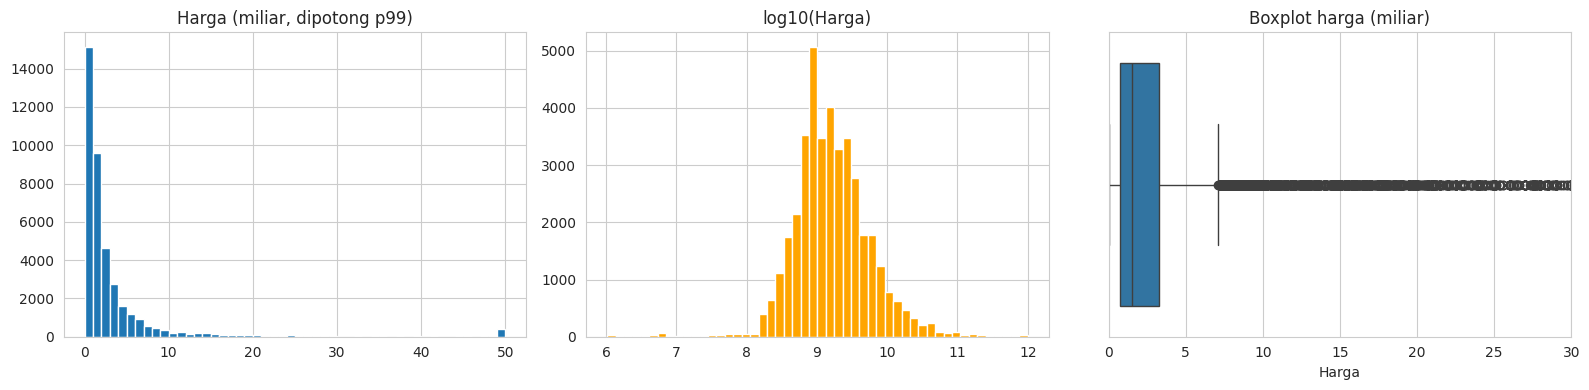

skewness harga      : 22.84984674071372
skewness log(harga) : 0.057929127005551306


In [ ]:
dd = d.dropna(subset=['Harga'])
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(dd['Harga'].clip(upper=dd['Harga'].quantile(0.99)) / 1e9, bins=50)
ax[0].set_title('Harga (miliar, dipotong p99)')
ax[1].hist(np.log10(dd['Harga']), bins=50, color='orange')
ax[1].set_title('log10(Harga)')
sns.boxplot(x=dd['Harga'] / 1e9, ax=ax[2])
ax[2].set_xlim(0, 30)
ax[2].set_title('Boxplot harga (miliar)')
plt.tight_layout()
plt.show()
print('skewness harga      :', dd['Harga'].skew())
print('skewness log(harga) :', np.log(dd['Harga']).skew())

Harga per kecamatan dan jumlah listing per label kecamatan.

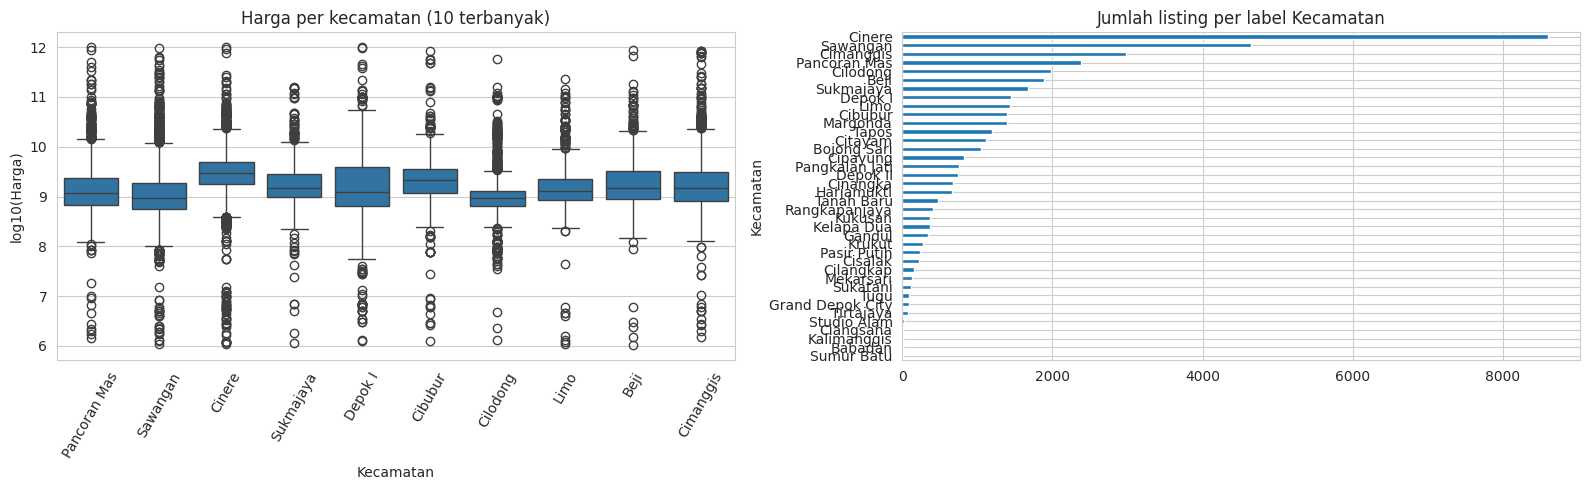

In [ ]:
top10 = dd['Kecamatan'].value_counts().head(10).index
sub10 = dd[dd['Kecamatan'].isin(top10)]
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=sub10, x='Kecamatan', y=np.log10(sub10['Harga']), ax=ax[0])
ax[0].set_ylabel('log10(Harga)')
ax[0].tick_params(axis='x', rotation=60)
ax[0].set_title('Harga per kecamatan (10 terbanyak)')
df['Kecamatan'].value_counts().plot(kind='barh', ax=ax[1])
ax[1].invert_yaxis()
ax[1].set_title('Jumlah listing per label Kecamatan')
plt.tight_layout()
plt.show()

Hubungan luas dengan harga (skala log) dan korelasi Spearman.

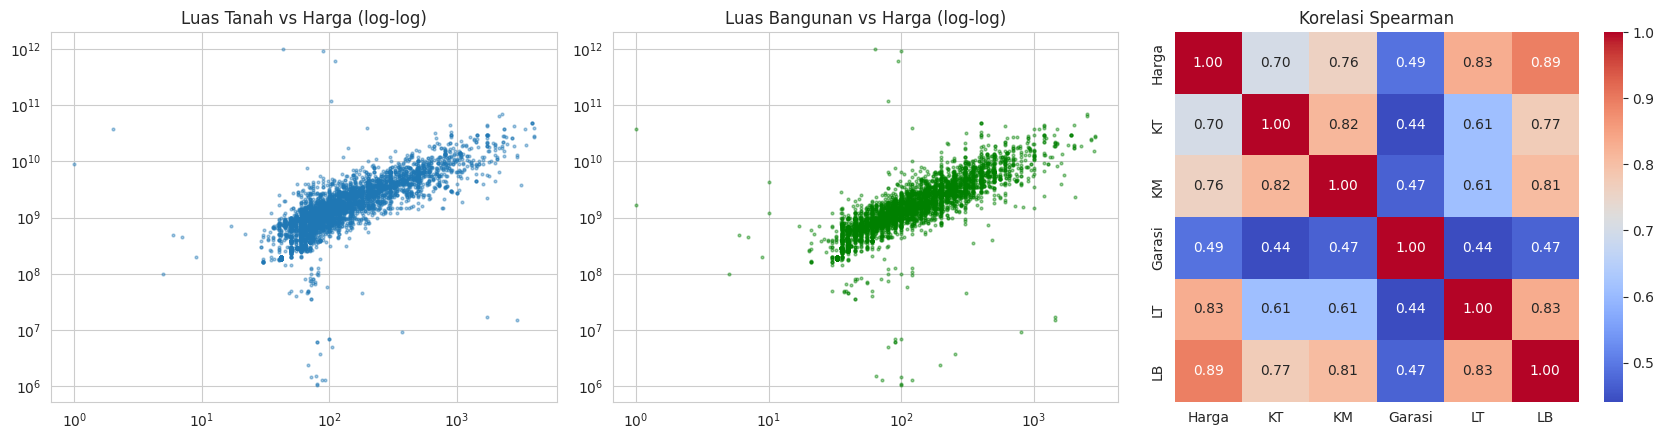

In [ ]:
s = dd[(dd['LT'] < 5000) & (dd['LB'] < 3000)].sample(5000, random_state=1)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(s['LT'], s['Harga'], s=4, alpha=0.4)
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_title('Luas Tanah vs Harga (log-log)')
ax[1].scatter(s['LB'], s['Harga'], s=4, alpha=0.4, color='green')
ax[1].set_xscale('log'); ax[1].set_yscale('log'); ax[1].set_title('Luas Bangunan vs Harga (log-log)')
korelasi = dd[['Harga', 'KT', 'KM', 'Garasi', 'LT', 'LB']].corr(method='spearman')
sns.heatmap(korelasi, annot=True, fmt='.2f', cmap='coolwarm', ax=ax[2])
ax[2].set_title('Korelasi Spearman')
plt.tight_layout()
plt.show()

Proporsi missing setelah kolom dirapikan.

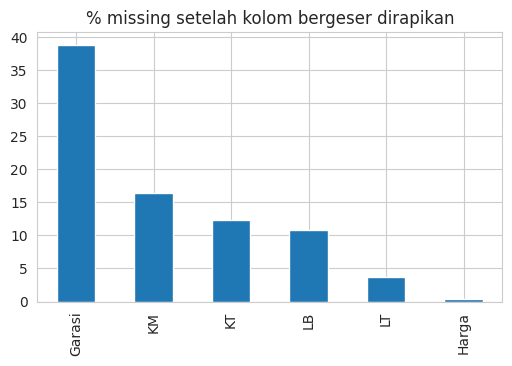

Harga            0.00
Kamar Tidur      0.00
Kamar Mandi     11.00
Garasi          12.90
Luas Tanah      19.20
Luas Bangunan   38.80
Kecamatan        0.00
Page             0.00
dtype: float64


In [ ]:
persen_missing = d.drop(columns='Kecamatan').isna().mean().sort_values(ascending=False) * 100
persen_missing.plot(kind='bar', figsize=(6, 3.5), title='% missing setelah kolom bergeser dirapikan')
plt.show()
print((df.isna().mean() * 100).round(1))

### 1.7 Insight dan keputusan

1. **Distribusi harga menceng ke kanan.** Skewness awal sekitar 22,8 dan turun menjadi sekitar 0,06 setelah transformasi log. Karena itu, target dilatih dalam skala log dan hasil prediksi dikembalikan ke rupiah untuk evaluasi.
2. **Luas bangunan dan luas tanah paling berkaitan dengan harga.** Keduanya memiliki korelasi Spearman tertinggi pada heatmap. LT/LB dan versi log-nya dicoba sebagai fitur; model berbasis pohon juga diuji karena hubungan harga tidak selalu linear.
3. **Label lokasi tidak selalu setingkat dan jumlah listing tiap lokasi berbeda.** Label yang bisa ditelusuri dipetakan ke kecamatan induk. Label yang jarang ditangani oleh `OneHotEncoder`, sedangkan label yang ambigu tidak dipaksakan untuk dipetakan.
4. **Ada listing yang mirip atau berulang.** Duplikat identik bisa dikenali dengan lebih pasti, sedangkan deduplikasi semantik hanya perkiraan karena tidak ada ID atau URL listing. Kandidat duplikat ditangani sebelum split agar risiko data serupa masuk ke train dan test berkurang.
5. **Ada kolom bergeser dan missing value, terutama pada luas.** LT/LB dicari berdasarkan labelnya, bukan hanya nama kolom. Sisa missing ditangani di dalam pipeline. Penanda missing juga dibuat, tetapi fitur tersebut tetap mengikuti hasil seleksi fitur dan tidak semuanya otomatis dipakai model.

## 2. Direct Modeling (kontrol)
Data **sengaja dibuat naif**: ambil angka pertama tiap kolom, NaN diisi 0, kecamatan di-label-encode, tanpa cleaning. Parser harganya juga naif (Triliun dan Ribu ikut dikali). Jadi hasil tahap ini mengukur dampak *seluruh* pembersihan data, bukan preprocessing yang terisolasi.

Alasan 5 model:
- **Linear Regression**: baseline hubungan linear.
- **KNN**: peka terhadap skala fitur dan tetangga terdekat.
- **Decision Tree**: menangkap hubungan non-linear, tidak peka skala.
- **Random Forest** (ensemble bagging): stabil dan lebih tahan outlier.
- **HistGradientBoosting** (ensemble boosting): kuat untuk data tabular dan menangani NaN.

In [ ]:
# versi paling naif: ambil angka pertama tiap kolom, NaN -> 0, tanpa cleaning apa pun
def harga_naif(teks):
    teks = str(teks)
    m = re.search(r'[\d,\.]+', teks)
    if m is None:
        return np.nan
    angka = float(m.group().replace(',', '.'))
    for satuan, kali in {'Triliun': 1e12, 'Miliar': 1e9, 'Juta': 1e6, 'Ribu': 1e3}.items():
        if satuan in teks:
            return angka * kali
    return np.nan

def angka_pertama(s):
    return pd.to_numeric(s.astype(str).str.extract(r'(\d+)')[0], errors='coerce')

raw = pd.DataFrame({'Harga': df['Harga'].map(harga_naif)})
for kolom in kolom_fitur:
    raw[kolom] = angka_pertama(df[kolom])
raw['Kecamatan'] = LabelEncoder().fit_transform(df['Kecamatan'])
raw = raw.dropna(subset=['Harga']).fillna(0)      # target kosong terpaksa dibuang
print(raw.shape)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    raw.drop(columns='Harga'), raw['Harga'], test_size=0.2, random_state=RANDOM_STATE)

(40159, 7)


Fungsi evaluasi melaporkan MAE, RMSE, MAPE, MedAPE, dan R² pada skala harga asli. Lima model dipakai sebagai pembanding. Jumlah pohon Random Forest di tahap baseline dibuat moderat supaya waktu komputasi wajar; konfigurasi final dicari di bagian Hyperparameter Tuning.

In [ ]:
def evaluasi(y_asli, y_pred):
    """MAE (juta rupiah), MAPE dan MedAPE (%), R2. Semua dihitung di skala rupiah asli."""
    y_asli = np.asarray(y_asli, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    if len(y_asli) != len(y_pred):
        raise ValueError('panjang target dan prediksi beda')
    if not (np.isfinite(y_asli).all() and np.isfinite(y_pred).all()):
        raise ValueError('ada nilai NaN/inf')
    if (y_asli <= 0).any():
        raise ValueError('MAPE butuh harga aktual > 0')

    ape = np.abs((y_asli - y_pred) / y_asli) * 100
    return {
        'MAE (juta)': mean_absolute_error(y_asli, y_pred) / 1e6,
        'RMSE (juta)': np.sqrt(mean_squared_error(y_asli, y_pred)) / 1e6,
        'MAPE (%)': ape.mean(),
        'MedAPE (%)': np.median(ape),
        'R2': r2_score(y_asli, y_pred),
    }

def daftar_model():
    return {
        'Linear Regression': LinearRegression(),
        'KNN': KNeighborsRegressor(n_neighbors=7),
        'Decision Tree': DecisionTreeRegressor(max_depth=12, random_state=RANDOM_STATE),
        'Random Forest': RandomForestRegressor(n_estimators=60, n_jobs=2, random_state=RANDOM_STATE),
        'HistGradientBoosting': HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    }

Latih 5 model pada data naif. Tahap ini memang sengaja tidak melakukan cleaning yang benar, jadi hasilnya hanya kontrol untuk menunjukkan dampak data mentah. Skor direct tidak dipakai untuk memilih model produksi.


In [ ]:
hasil = {}
for nama, model in daftar_model().items():
    model.fit(Xr_train, yr_train)
    hasil[nama] = evaluasi(yr_test, model.predict(Xr_test))

res_direct_awal = pd.DataFrame(hasil).T
res_direct_awal

,MAE (juta),RMSE (juta),MAPE (%),MedAPE (%),R2
Linear Regression,"4,919,316.86","420,661,501.91","356,299.39","8,927.39","-3,704.56"
KNN,"335,271.90","8,661,145.84","5,326.02",16.09,-0.57
Decision Tree,"329,726.64","21,422,153.77","10,242.72",87.21,-8.61
Random Forest,"270,160.39","10,636,789.02","14,299.44",11.46,-1.37
HistGradientBoosting,"302,174.42","7,218,962.15","48,737.90","5,810.75",-0.09


## 3. Preprocessing
Urutannya: parsing harga, deduplikasi, pemeriksaan fitur yang tidak masuk akal, pemetaan lokasi yang bisa diverifikasi, lalu pembagian data. Harga-per-luas dipakai untuk pemeriksaan, bukan untuk membuang baris test setelah split.


In [ ]:
# 1) buang baris yang harganya tidak bisa diparse
c = d.dropna(subset=['Harga']).copy()
print('setelah buang harga tidak valid:', len(c))

# 2) duplikat
kunci = ['Harga', 'KT', 'KM', 'Garasi', 'LT', 'LB']
punya_luas = c['LT'].notna() & c['LB'].notna()

n_tanpa_kec = len(c.drop_duplicates(kunci))
n_dengan_kec = len(c.drop_duplicates(kunci + ['Kecamatan']))

# LT dan LB ada -> identitas listing kuat, label Kecamatan diabaikan (labelnya cuma beda tingkat wilayah)
# salah satu kosong -> identitas lemah, Kecamatan ikut jadi kunci supaya rumah beda tidak ikut terbuang
c = pd.concat([
    c[punya_luas].drop_duplicates(kunci),
    c[~punya_luas].drop_duplicates(kunci + ['Kecamatan']),
]).sort_index()

print('sisa kalau Kecamatan selalu diabaikan :', n_tanpa_kec)
print('sisa kalau Kecamatan selalu dipakai   :', n_dengan_kec)
print('sisa dengan aturan gabungan (dipakai) :', len(c))

setelah buang harga tidak valid: 40024
sisa kalau Kecamatan selalu diabaikan : 27677
sisa kalau Kecamatan selalu dipakai   : 30533
sisa dengan aturan gabungan (dipakai) : 28207


Deduplikasi semantik masih berupa perkiraan karena dataset tidak punya URL atau ID listing. Jika LT dan LB tersedia, harga dan spesifikasi dipakai untuk mencari kandidat duplikat, tanpa memakai Kecamatan sebagai bagian kunci. Jika luas belum lengkap, Kecamatan ikut dipakai agar risiko menghapus rumah berbeda lebih kecil. Aturan ini membantu mengurangi duplikasi, tetapi tidak membuktikan bahwa dua baris berasal dari listing yang sama.


Aturan domain untuk eksperimen ini: target harga total dipertahankan pada rentang Rp100 juta–Rp100 miliar. Rentang ini merupakan **cakupan proyek**, bukan aturan universal untuk semua properti. Nilai fitur yang tidak masuk akal lebih baik ditandai sebagai missing jika target listing masih bisa digunakan, supaya satu kesalahan kolom tidak langsung menghilangkan seluruh baris.


In [ ]:
# 3) aturan domain yang ditetapkan sebelum split
# Area kecil/amat besar atau jumlah ruang yang tidak masuk akal ditandai sebagai missing.
# Baris tetap dipertahankan jika harga totalnya masih berada di cakupan proyek.
for kolom, batas_atas in [('LT', 100_000), ('LB', 10_000)]:
    rendah = c[kolom] < 10
    tinggi = c[kolom] > batas_atas
    print(kolom, '| nilai < 10 m2:', int(rendah.sum()), '| nilai >', f'{batas_atas:,}', 'm2:', int(tinggi.sum()))
    c.loc[rendah | tinggi, kolom] = np.nan

for kolom in ['KT', 'KM', 'Garasi']:
    tidak_wajar = c[kolom] > 10
    print(kolom, '| nilai > 10 ditandai missing:', int(tidak_wajar.sum()))
    c.loc[tidak_wajar, kolom] = np.nan

n0 = len(c)
c = c[c['Harga'].between(1e8, 1e11)].copy()
print('harga di luar cakupan Rp100 juta–Rp100 miliar:', n0 - len(c), '-> sisa', len(c))


LT | nilai < 10 m2: 41 | nilai > 100,000 m2: 19
LB | nilai < 10 m2: 28 | nilai > 10,000 m2: 24
KT | nilai > 10 ditandai missing: 415
KM | nilai > 10 ditandai missing: 320
Garasi | nilai > 10 ditandai missing: 63
harga di luar cakupan Rp100 juta–Rp100 miliar: 539 -> sisa 27668


Pemetaan kecamatan hanya untuk label yang bisa ditelusuri ke daftar kelurahan resmi (tabel di bawah memuat sumbernya). Label ambigu seperti Margonda (nama jalan, bukan kelurahan), Cisalak (ada di dua kecamatan), Citayam, Kelapa Dua, dan Cibubur **tidak dipetakan**. Garasi kosong **tidak diisi 0** secara paksa: artinya belum tentu "tidak ada garasi". Kekosongan (termasuk Garasi) ditangani di bagian *Penanganan missing value* di bawah.

In [ ]:
# 4) samakan level kecamatan. hanya label yang terbukti dipetakan; yang ambigu dibiarkan apa adanya
peta_kec = pd.DataFrame([
    ('Kukusan',        'Beji',         'Daftar kelurahan Kec. Beji (BAB II Faqih, UNDIP)'),
    ('Tanah Baru',     'Beji',         'Idem ("Tanahbaru")'),
    ('Depok I',        'Beji',         'Perumnas Depok I ada di Kec. Beji (jurnal UNSRI)'),
    ('Depok II',       'Sukmajaya',    'Depok Dua Tengah/Timur ada di Kec. Sukmajaya (Wikipedia)'),
    ('Tirtajaya',      'Sukmajaya',    'Daftar kelurahan Kec. Sukmajaya'),
    ('Rangkapanjaya',  'Pancoran Mas', 'Daftar kelurahan Kec. Pancoran Mas ("Rangkapan Jaya")'),
    ('Krukut',         'Limo',         'Daftar kelurahan Kec. Limo'),
    ('Pangkalan Jati', 'Cinere',       'Daftar kelurahan Kec. Cinere'),
    ('Gandul',         'Cinere',       'Idem'),
    ('Pasir Putih',    'Sawangan',     'Daftar kelurahan Kec. Sawangan'),
    ('Cinangka',       'Sawangan',     'Idem'),
    ('Bojong Sari',    'Bojongsari',   'Nama kecamatan, ejaan beda'),
    ('Harjamukti',     'Cimanggis',    'Daftar kelurahan Kec. Cimanggis'),
    ('Tugu',           'Cimanggis',    'Idem'),
    ('Mekarsari',      'Cimanggis',    'Idem'),
    ('Cilangkap',      'Tapos',        'Daftar kelurahan Kec. Tapos'),
    ('Sukatani',       'Tapos',        'Idem'),
], columns=['label_asli', 'kecamatan', 'sumber'])
display(peta_kec)
print('sengaja TIDAK dipetakan (ambigu / bukan kelurahan resmi): Margonda, Cisalak, Citayam, Kelapa Dua, Cibubur, dll')

c['Kecamatan'] = c['Kecamatan'].replace(dict(zip(peta_kec['label_asli'], peta_kec['kecamatan'])))
c['idx_asli'] = c.index                  # index baris di data mentah, dipakai lagi buat perbandingan adil
bersih = c.reset_index(drop=True)

# label langka (< 100 baris) hanya dilumpuhkan untuk strata split.
# di model, label langka ditangani OneHotEncoder(min_frequency) yang belajar dari data train saja
frek = bersih['Kecamatan'].value_counts()
bersih['kec_strata'] = bersih['Kecamatan'].where(bersih['Kecamatan'].map(frek) >= 100, 'Lainnya')
print(frek)
print(bersih.shape)

,label_asli,kecamatan,sumber
0,Kukusan,Beji,"Daftar kelurahan Kec. Beji (BAB II Faqih, UNDIP)"
1,Tanah Baru,Beji,"Idem (""Tanahbaru"")"
2,Depok I,Beji,Perumnas Depok I ada di Kec. Beji (jurnal UNSRI)
3,Depok II,Sukmajaya,Depok Dua Tengah/Timur ada di Kec. Sukmajaya (...
4,Tirtajaya,Sukmajaya,Daftar kelurahan Kec. Sukmajaya
5,Rangkapanjaya,Pancoran Mas,"Daftar kelurahan Kec. Pancoran Mas (""Rangkapan..."
6,Krukut,Limo,Daftar kelurahan Kec. Limo
7,Pangkalan Jati,Cinere,Daftar kelurahan Kec. Cinere
8,Gandul,Cinere,Idem
9,Pasir Putih,Sawangan,Daftar kelurahan Kec. Sawangan


sengaja TIDAK dipetakan (ambigu / bukan kelurahan resmi): Margonda, Cisalak, Citayam, Kelapa Dua, Cibubur, dll
Kecamatan
Cinere              6740
Sawangan            3794
Beji                2941
Cimanggis           2838
Sukmajaya           1920
Pancoran Mas        1752
Cilodong            1481
Limo                1157
Tapos               1015
Cibubur             1013
Margonda             972
Bojongsari           696
Cipayung             447
Citayam              437
Kelapa Dua           229
Cisalak              147
Grand Depok City      60
Studio Alam           10
Ciangsana              9
Kalimanggis            6
Babadan                4
Name: count, dtype: Int64
(27668, 9)


### Feature engineering
`Garasi_hilang`, `LB_hilang`, `LT_hilang`, `total_kamar`, `rasio_LB_LT`, dan versi log LT/LB. Harga per m² tidak dipakai sebagai fitur karena memakai target (leakage). Fungsi `buat_fitur` ini disalin persis ke `app.py` supaya input Streamlit diproses sama seperti saat training.

In [ ]:
def buat_fitur(x):
    """Feature engineering; nilai 0 tetap dipertahankan dan missing tetap NaN."""
    x = x.copy()
    for kolom in ['KT', 'KM', 'Garasi', 'LT', 'LB']:
        x[kolom] = pd.to_numeric(x[kolom], errors='coerce')
    x['Garasi_hilang'] = x['Garasi'].isna().astype(int)
    x['LB_hilang'] = x['LB'].isna().astype(int)
    x['LT_hilang'] = x['LT'].isna().astype(int)
    x['total_kamar'] = x['KT'] + x['KM']
    x['rasio_LB_LT'] = x['LB'] / x['LT'].replace(0, np.nan)
    x['log_LT'] = np.log1p(x['LT'].clip(lower=0))
    x['log_LB'] = np.log1p(x['LB'].clip(lower=0))
    return x

fitur_num = ['KT', 'KM', 'Garasi', 'LT', 'LB', 'Garasi_hilang', 'LB_hilang', 'LT_hilang',
             'total_kamar', 'rasio_LB_LT', 'log_LT', 'log_LB']
fitur_cat = ['Kecamatan']

def pisah_fitur(daftar):
    """Daftar fitur -> (kolom numerik, kolom kategori)."""
    return [f for f in daftar if f not in fitur_cat], [f for f in daftar if f in fitur_cat]

data = buat_fitur(bersih)
X = data[fitur_num + fitur_cat]
y = data['Harga']
X.head()


,KT,KM,Garasi,LT,LB,Garasi_hilang,LB_hilang,LT_hilang,total_kamar,rasio_LB_LT,log_LT,log_LB,Kecamatan
0,4.00,3.00,10.00,438.00,110.00,0,0,0,7.00,0.25,6.08,4.71,Tapos
1,3.00,2.00,1.00,50.00,60.00,0,0,0,5.00,1.20,3.93,4.11,Pancoran Mas
2,2.00,1.00,1.00,87.00,50.00,0,0,0,3.00,0.57,4.48,3.93,Sawangan
3,2.00,1.00,NaN,NaN,41.00,1,0,1,3.00,NaN,NaN,3.74,Cinere
4,3.00,2.00,NaN,409.00,300.00,1,0,0,5.00,0.73,6.02,5.71,Sukmajaya


### Split data
Target kontinu tidak bisa distratifikasi langsung: harga dibagi 5 bin (kuantil log harga) lalu digabung dengan kecamatan. Test set 20%.

In [ ]:
# strata = bin harga (5 kuantil log harga) + kecamatan
bin_harga = pd.qcut(np.log(y), 5, labels=False)
strata = bin_harga.astype(str) + '_' + data['kec_strata']
print('jumlah strata:', strata.nunique(), '| terkecil:', strata.value_counts().min())

X_train, X_test, y_train, y_test, s_train, s_test = train_test_split(
    X, y, strata, test_size=0.2, stratify=strata, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

jumlah strata: 85 | terkecil: 7
(22134, 13) (5534, 13)


### Pemeriksaan nilai ekstrem sebelum modeling
Nilai harga per m² dipakai untuk **diagnosis**, bukan untuk menyaring test set setelah split. Filter berdasarkan harga aktual pada test bisa membuat evaluasi terlihat lebih baik daripada penggunaan sebenarnya. Karena itu, semua listing dengan target valid di cakupan proyek tetap berada di test set; nilai area yang sangat mencurigakan sudah ditandai pada tahap domain sebelum split.


In [ ]:
# Ringkasan harga-per-luas untuk diagnosis saja; tidak dipakai untuk membuang baris setelah split.
for fitur in ['LT', 'LB']:
    rasio = y_train / X_train[fitur].replace(0, np.nan)
    valid = rasio.replace([np.inf, -np.inf], np.nan).dropna()
    if len(valid):
        print(f'Harga / {fitur} (train) | median: Rp{valid.median():,.0f} per m2 | p99: Rp{valid.quantile(.99):,.0f}')

# Test set tidak disaring berdasarkan target/harga per luas.
print('Tidak ada observasi test yang dibuang setelah split:', len(X_test))
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train, s_train))
print('train:', X_train.shape, '| test:', X_test.shape, '| strata terkecil di train:', s_train.value_counts().min())
print('jumlah fold:', len(folds))


Harga / LT (train) | median: Rp11,727,293 per m2 | p99: Rp40,000,000
Harga / LB (train) | median: Rp13,116,667 per m2 | p99: Rp45,238,144
Tidak ada observasi test yang dibuang setelah split: 5534
train: (22134, 13) | test: (5534, 13) | strata terkecil di train: 6
jumlah fold: 5


### Direct Modeling di test set yang sama
Model direct memakai parsing yang sengaja naif, jadi hasilnya hanya kontrol untuk menunjukkan dampak kualitas data. Test rows mengikuti split final yang sama, sementara baris dengan spesifikasi yang cocok dikeluarkan dari data latih direct sejauh bisa dikenali tanpa ID listing. Nilai direct bukan kandidat model produksi.


In [ ]:
# perbandingan kontrol: model direct (data naif) diuji di test set yang sama.
# baris mentah yang spesifikasinya cocok dengan baris test dikeluarkan dari data latih direct
# (tanpa ID listing, kecocokan ini hanya perkiraan; Kecamatan sengaja tidak dipakai supaya lebih konservatif)
asli_test = bersih.loc[X_test.index, 'idx_asli']
kunci_cocok = ['Harga', 'KT', 'KM', 'Garasi', 'LT', 'LB']
semua_kunci = pd.MultiIndex.from_frame(d[kunci_cocok].fillna(-1))
kunci_test = pd.MultiIndex.from_frame(d.loc[asli_test, kunci_cocok].fillna(-1))
mirip_test = pd.Series(semua_kunci.isin(kunci_test), index=d.index)

idx_latih = raw.index[~mirip_test.loc[raw.index].values & ~raw.index.isin(asli_test)]
Xd_train, yd_train = raw.loc[idx_latih].drop(columns='Harga'), raw.loc[idx_latih, 'Harga']
Xd_test = raw.loc[asli_test].drop(columns='Harga')
print('data latih direct:', len(Xd_train), '| test bersih:', len(Xd_test))

hasil = {}
for nama, model in daftar_model().items():
    model.fit(Xd_train, yd_train)
    hasil[nama] = evaluasi(y_test, model.predict(Xd_test))

res_direct = pd.DataFrame(hasil).T
res_direct

data latih direct: 31649 | test bersih: 5534


,MAE (juta),RMSE (juta),MAPE (%),MedAPE (%),R2
Linear Regression,"147,559.46","155,395.83","12,857.89","8,323.57",-438.65
KNN,"270,810.89","7,242,473.07","1,268.39",20.73,"-954,988.12"
Decision Tree,"160,229.36","5,701,557.60",736.51,63.80,"-591,849.03"
Random Forest,"164,697.73","4,267,170.54","1,108.33",18.06,"-331,515.11"
HistGradientBoosting,"160,497.41","1,450,151.77","8,084.58","5,614.59","-38,286.02"


### Pipeline
Imputasi + scaling untuk numerik (metode imputasi diputuskan di bagian Penanganan missing value), one-hot untuk kecamatan (label dengan < 80 baris di train otomatis digabung), semuanya di dalam `Pipeline` sehingga hanya di-fit pada data train. Target di-log lewat `TransformedTargetRegressor`.

In [ ]:
def buat_encoder():
    try:     # label langka (< 80 baris di train) otomatis digabung jadi satu kolom "infrequent"
        return OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=80, sparse_output=False)
    except TypeError:     # scikit-learn versi lama
        return OneHotEncoder(handle_unknown='ignore', sparse=False)

IMPUTASI = 'median'       # metode imputasi aktif; diputuskan lewat uji di bagian "Penanganan missing value"

def buat_pipeline(model, kolom_num, kolom_cat, imputasi=None):
    """imputasi + scaling untuk numerik, one-hot untuk kategori; target di-log lalu dibalik ke rupiah"""
    imputasi = imputasi or IMPUTASI
    flag = [k for k in kolom_num if k.endswith('_hilang')]       # penanda missing (0/1) tidak diimputasi
    angka = [k for k in kolom_num if k not in flag]

    if imputasi == 'mice':
        # MICE: tiap kolom yang kosong diprediksi dari kolom lain pakai BayesianRidge.
        # dikerjakan di skala log karena luas tanah/bangunan sangat miring
        proses = Pipeline([('log', FunctionTransformer(np.log1p)),
                           ('imp', IterativeImputer(BayesianRidge(), max_iter=3, random_state=RANDOM_STATE)),
                           ('sc', StandardScaler())])
    else:
        proses = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())])

    langkah = [('num', proses, angka)]
    if flag:
        langkah.append(('flag', 'passthrough', flag))
    if kolom_cat:
        langkah.append(('cat', buat_encoder(), kolom_cat))
    pipe = Pipeline([('prep', ColumnTransformer(langkah)), ('model', model)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

def evaluasi_semua(kolom_num, kolom_cat):
    """latih 5 model pada fitur yang diberikan, evaluasi di test set bersih"""
    kolom = kolom_num + kolom_cat
    hasil = {}
    for nama, model in daftar_model().items():
        pipe = buat_pipeline(model, kolom_num, kolom_cat).fit(X_train[kolom], y_train)
        hasil[nama] = evaluasi(y_test, pipe.predict(X_test[kolom]))
    return pd.DataFrame(hasil).T

### Penanganan missing value
Setelah kolom dirapikan, nilai kosong masih ditemukan pada KT (sekitar 12%), KM (16%), Garasi (41%), LT (4%), dan LB (10%). Ada dua hal yang dibedakan:
- **Penanda kosong** (`Garasi_hilang`, `LB_hilang`, `LT_hilang`) selalu dipertahankan, karena kosong itu sendiri bisa informatif (listing tanpa luas bangunan biasanya tanah).
- **Nilai pengisinya** dipilih lewat uji, bukan diasumsikan. Kandidat: median (sederhana) dan **MICE** (`IterativeImputer` dengan `BayesianRidge`: tiap kolom yang kosong diprediksi dari kolom lainnya). MICE diuji di skala log karena luas sangat miring.

Dua uji: (1) seberapa akurat imputer menebak nilai yang sengaja disembunyikan, (2) apakah imputer itu membuat prediksi harga lebih baik. Imputasi dilakukan di dalam pipeline, jadi di CV hanya belajar dari fold latih.

**Uji 1: akurasi tebakan.** Sebagian nilai yang diketahui disembunyikan (20%, acak), lalu tebakan imputer dibandingkan dengan nilai aslinya. Catatan: uji ini mengasumsikan nilai hilang acak, padahal kekosongan asli di data ini kemungkinan tidak acak.

In [ ]:
# Uji imputasi: sembunyikan sebagian nilai pada baris yang lengkap, lalu lihat error tebakan.
# Sampel dibatasi supaya eksperimen pendukung ini tetap ringan.
kolom_base = ['KT', 'KM', 'Garasi', 'LT', 'LB']
B_all = X_train[kolom_base].values.astype(float)
lengkap_awal = ~np.isnan(B_all[:, [0, 1, 3, 4]]).any(axis=1)
idx_lengkap = np.flatnonzero(lengkap_awal)
rng_sampel = np.random.default_rng(RANDOM_STATE)
if len(idx_lengkap) > 2500:
    idx_lengkap = rng_sampel.choice(idx_lengkap, 2500, replace=False)
B = B_all[idx_lengkap]
print('baris lengkap yang diuji:', len(B), '| sampel dibatasi maksimal 2.500 baris')

kandidat = {
    'Median': (lambda: SimpleImputer(strategy='median'), False),
    'MICE BayesianRidge, skala log': (lambda: IterativeImputer(BayesianRidge(), max_iter=3, random_state=RANDOM_STATE), True),
}

def uji_imputer(buat, pakai_log, seed):
    rng = np.random.default_rng(seed)
    mask = np.zeros(B.shape, bool)
    for j in [0, 1, 3, 4]:
        mask[:, j] = rng.random(len(B)) < 0.2
    Bm = B.copy()
    Bm[mask] = np.nan
    hat = buat().fit_transform(np.log1p(Bm) if pakai_log else Bm)
    if pakai_log:
        hat = np.expm1(hat)
    hasil = {}
    for j, nama in [(3, 'LT'), (4, 'LB')]:
        m = mask[:, j]
        hasil[nama + ' galat median (%)'] = np.median(np.abs(hat[m, j] - B[m, j]) / np.maximum(B[m, j], 1)) * 100
    for j, nama in [(0, 'KT'), (1, 'KM')]:
        m = mask[:, j]
        hasil[nama + ' MAE (kamar)'] = np.abs(hat[m, j] - B[m, j]).mean()
    return hasil

tabel_akurasi = pd.DataFrame({nama: pd.DataFrame([uji_imputer(b, lg, 42)]).mean()
                              for nama, (b, lg) in kandidat.items()}).T
tabel_akurasi


baris lengkap yang diuji: 2500 | sampel dibatasi maksimal 2.500 baris


,LT galat median (%),LB galat median (%),KT MAE (kamar),KM MAE (kamar)
Median,49.33,49.33,0.91,0.88
"MICE BayesianRidge, skala log",29.11,23.23,0.58,0.55


Hasil uji ini hanya mengukur kemampuan menebak nilai yang sengaja disembunyikan pada subset data yang lebih lengkap. Hasilnya bukan bukti bahwa pola missing asli bersifat acak. Untuk memilih metode imputasi, hasil ini dibandingkan lagi dengan performa prediksi harga pada uji CV berikutnya.

**Uji 2: dampak ke prediksi harga.** Untuk menghemat resource, uji ini memakai satu holdout kecil dengan Random Forest. Hasilnya dipakai sebagai pembanding awal saja; kualitas model akhir tetap ditentukan lewat CV dan evaluasi test set.

In [ ]:
# Uji singkat dampak imputasi ke prediksi harga. Ini pembanding awal, bukan metrik final.
kolom_uji = fitur_num + fitur_cat
idx_imp = X_train.sample(n=min(2500, len(X_train)), random_state=RANDOM_STATE).index
X_imp, y_imp = X_train.loc[idx_imp, kolom_uji], y_train.loc[idx_imp]
X_imp_train, X_imp_val, y_imp_train, y_imp_val = train_test_split(
    X_imp, y_imp, test_size=0.25, random_state=RANDOM_STATE)

skor_imp = {}
model_uji = RandomForestRegressor(n_estimators=30, max_depth=14, min_samples_leaf=2,
                                  n_jobs=2, random_state=RANDOM_STATE)
for metode in ['median', 'mice']:
    pipe = buat_pipeline(model_uji, fitur_num, fitur_cat, imputasi=metode)
    pipe.fit(X_imp_train, y_imp_train)
    skor_imp[metode] = mean_absolute_error(y_imp_val, pipe.predict(X_imp_val)) / 1e6

tabel_imp = pd.DataFrame.from_dict(skor_imp, orient='index', columns=['MAE validasi (juta)'])
display(tabel_imp)
# Selisih satu holdout belum cukup kuat untuk memilih imputer yang lebih kompleks.
# Median dipakai sebagai pilihan awal karena lebih sederhana dan jauh lebih ringan.
IMPUTASI = 'median'
print('imputasi yang dipakai selanjutnya:', IMPUTASI)


,MAE validasi (juta)
median,"1,326.66"
mice,"1,304.02"


imputasi yang dipakai selanjutnya: median


Hasil validasi kecil bisa berubah pada split lain. Jika MICE sedikit lebih baik pada satu holdout, perbedaan itu belum cukup untuk menyimpulkan peningkatan yang stabil. Untuk notebook final, median dipakai karena sederhana, cepat, dan lebih mudah direproduksi; MICE tetap ditampilkan sebagai pembanding, bukan otomatis dipilih dari satu split.

Model yang sama dengan direct, dilatih pada data bersih dan diuji di test set.

In [ ]:
res_prep = evaluasi_semua(fitur_num, fitur_cat)
res_prep

,MAE (juta),RMSE (juta),MAPE (%),MedAPE (%),R2
Linear Regression,"1,385.50","4,644.76",35.42,23.33,0.61
KNN,"1,262.52","4,061.93",32.82,20.52,0.70
Decision Tree,"1,196.68","3,909.34",34.05,19.03,0.72
Random Forest,"1,022.72","3,523.57",28.87,15.31,0.77
HistGradientBoosting,"1,192.14","3,959.37",29.77,19.53,0.71


### Validasi internal
Sebagian data train (20%) dipisahkan sebagai validasi internal untuk feature selection. Test set tidak disentuh.

In [ ]:
# validasi internal dari data train: dipakai untuk uji asumsi Garasi dan memilih fitur. Test set tidak disentuh.
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=RANDOM_STATE)
print(X_fit.shape, X_val.shape)

(17707, 13) (4427, 13)


## 4. Feature Selection
Tiga metode dihitung **hanya dari data fit** (bukan seluruh train): korelasi Spearman, Mutual Information, dan importance Random Forest. Kecamatan di-one-hot lalu skornya dijumlah menjadi satu fitur lokasi (tidak di-label-encode karena kategori nominal tidak punya urutan). Fitur yang kembar (LT dengan log_LT, LB dengan log_LB) membuat importance terbagi, jadi ketiga peringkat digabung dan jumlah fitur ditentukan dari performa di validasi internal.

In [ ]:
# peringkat fitur dihitung hanya dari X_fit
fit_log = np.log(y_fit)
spearman = X_fit[fitur_num].corrwith(fit_log, method='spearman').abs()

# Kecamatan di-one-hot dulu (bukan label-encode), lalu skor kolom-kolomnya dijumlah jadi satu fitur lokasi
dummies = pd.get_dummies(X_fit, columns=fitur_cat, dtype=float)
dummies = dummies.fillna(dummies.median())
kolom_kec = [k for k in dummies.columns if k.startswith('Kecamatan_')]

def gabung_kec(skor):
    hasil = skor.drop(kolom_kec)
    hasil['Kecamatan'] = skor[kolom_kec].sum()
    return hasil

mi = pd.Series(mutual_info_regression(dummies, fit_log, discrete_features=[k in kolom_kec for k in dummies.columns],
                                      random_state=RANDOM_STATE), index=dummies.columns)
rf = RandomForestRegressor(n_estimators=70, max_depth=12, n_jobs=2, random_state=RANDOM_STATE).fit(dummies, fit_log)
imp = pd.Series(rf.feature_importances_, index=dummies.columns)

tabel_fs = pd.DataFrame({'Spearman |r|': spearman, 'Mutual Info': gabung_kec(mi), 'RF Importance': gabung_kec(imp)})
tabel_fs.sort_values('RF Importance', ascending=False)

,Spearman |r|,Mutual Info,RF Importance
log_LT,0.83,0.88,0.38
LT,0.83,0.87,0.33
LB,0.88,0.87,0.11
log_LB,0.88,0.88,0.10
Kecamatan,NaN,0.25,0.04
rasio_LB_LT,0.06,0.30,0.01
KM,0.73,0.31,0.01
total_kamar,0.76,0.37,0.01
LB_hilang,0.22,0.06,0.01
KT,0.67,0.28,0.00


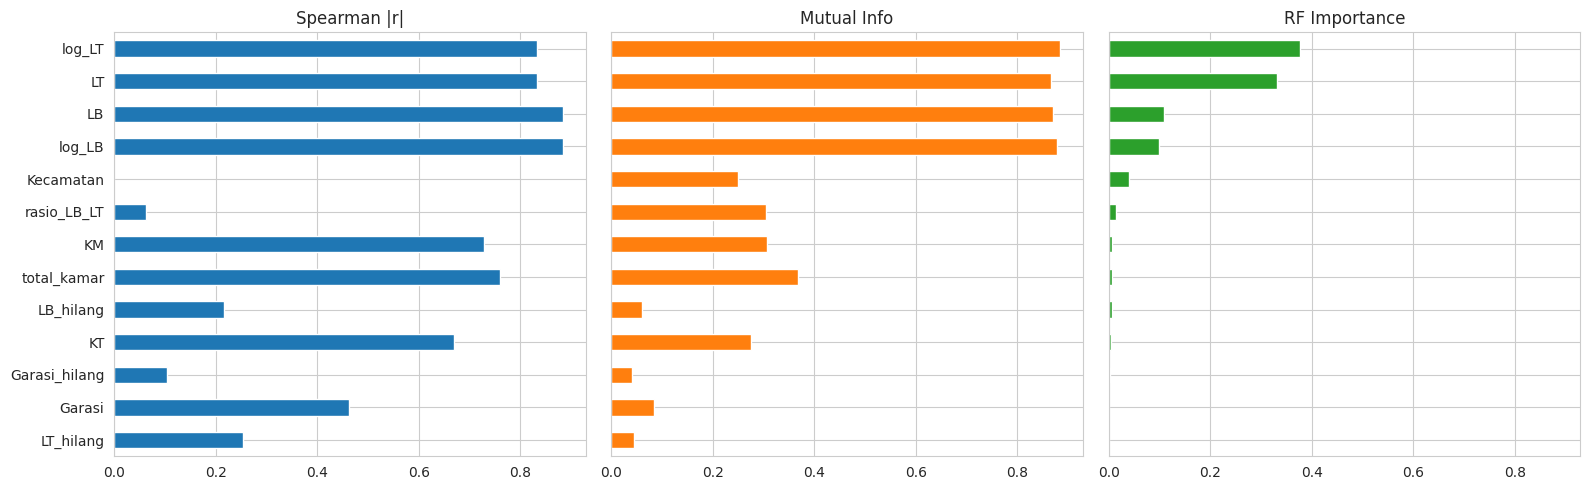

In [ ]:
tabel_fs.sort_values('RF Importance').plot(kind='barh', subplots=True, layout=(1, 3), figsize=(16, 5), legend=False, sharey=True)
plt.tight_layout()
plt.show()

Jumlah fitur k dipilih dari MAE validasi (HistGradientBoosting). Aturannya: ambil k terkecil yang MAE-nya masih dalam 1% dari yang terbaik, supaya model sesederhana mungkin kalau skornya setara.

In [ ]:
# rata-rata peringkat 3 metode (Spearman kosong untuk Kecamatan, jadi dirata-rata dari yang tersedia)
urut = tabel_fs.rank(ascending=False).mean(axis=1).sort_values().index.tolist()
print('urutan fitur:', urut)

# jumlah fitur k dipilih dari MAE di validasi internal
skor_k = {}
for k in [4, 6, 8, 10, len(urut)]:
    kn, kc = pisah_fitur(urut[:k])
    pipe = buat_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE), kn, kc).fit(X_fit[kn + kc], y_fit)
    skor_k[k] = mean_absolute_error(y_val, pipe.predict(X_val[kn + kc])) / 1e6
    print('k =', k, '| MAE validasi (juta):', round(skor_k[k], 1))

# aturan: ambil k terkecil yang MAE-nya masih dalam 1% dari yang terbaik (model lebih sederhana kalau skornya setara)
mae_terbaik = min(skor_k.values())
k_terbaik = min(k for k, skor in skor_k.items() if skor <= mae_terbaik * 1.01)
fitur_terpilih = urut[:k_terbaik]
num_sel, cat_sel = pisah_fitur(fitur_terpilih)
kolom = num_sel + cat_sel
print('k terbaik:', k_terbaik)
print('terpilih:', fitur_terpilih)
print('dibuang :', [f for f in urut if f not in fitur_terpilih])

urutan fitur: ['log_LT', 'LB', 'log_LB', 'LT', 'total_kamar', 'KM', 'Kecamatan', 'KT', 'rasio_LB_LT', 'Garasi', 'LB_hilang', 'LT_hilang', 'Garasi_hilang']
k = 4 | MAE validasi (juta): 1307.9
k = 6 | MAE validasi (juta): 1268.2
k = 8 | MAE validasi (juta): 1140.6
k = 10 | MAE validasi (juta): 1142.8
k = 13 | MAE validasi (juta): 1141.5
k terbaik: 8
terpilih: ['log_LT', 'LB', 'log_LB', 'LT', 'total_kamar', 'KM', 'Kecamatan', 'KT']
dibuang : ['rasio_LB_LT', 'Garasi', 'LB_hilang', 'LT_hilang', 'Garasi_hilang']


Model dilatih ulang dengan fitur terpilih. Pada hasil ini, skor Random Forest masih relatif mirip (R² sekitar 0,77). Linear Regression turun sedikit, dari R² sekitar 0,61 menjadi 0,57. Pengurangan fitur tidak selalu meningkatkan hasil semua model.

In [37]:
res_fs = evaluasi_semua(num_sel, cat_sel)
res_fs

,MAE (juta),RMSE (juta),MAPE (%),MedAPE (%),R2
Linear Regression,"1,442.57","4,854.45",37.98,24.36,0.57
KNN,"1,246.82","4,004.09",33.04,19.84,0.71
Decision Tree,"1,194.38","3,857.02",34.68,18.94,0.73
Random Forest,"1,020.21","3,528.46",28.80,15.14,0.77
HistGradientBoosting,"1,207.85","3,978.02",30.43,19.60,0.71


## 5. Hyperparameter Tuning
Tuning dilakukan pada data latih. Test set dipakai untuk evaluasi akhir, bukan untuk memilih parameter:
1. **Baseline** = konfigurasi model tahap sebelumnya, dihitung dengan CV 5-fold yang sama (terstratifikasi kuantil harga x kecamatan) pada **seluruh 22 ribu baris data latih**, supaya perbandingan default vs tuning adil.
2. **RandomizedSearchCV** dengan distribusi parameter (`randint`, `uniform`, `loguniform`), bukan grid kecil. Skor MAE, MAPE, dan R2 dihitung pada skala rupiah; parameter terbaik dipilih berdasarkan **MAE** (metrik utama proyek).
3. **Aturan keputusan:** hasil tuning dipakai hanya jika CV MAE-nya lebih baik daripada baseline; jika tidak, model tetap default. Aturan ini dari CV, bukan dari test set.
4. Model dilatih ulang pada seluruh data latih, lalu dievaluasi **satu kali** di test set bersih.

Catatan: Linear Regression tidak punya hyperparameter yang perlu dicari. HistGradientBoosting memakai early stopping agar jumlah iterasi tidak berlebihan. Random Forest dikunci 100 pohon agar ukuran file model tetap layak untuk GitHub dan Streamlit Cloud (300 pohon dengan daun minimum 1 menghasilkan file >100 MB).

In [38]:
# Hyperparameter tuning
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import cross_validate

pre = 'regressor__model__'
N_JOBS = -1 if os.cpu_count() and os.cpu_count() > 1 else 1   # Colab 2 core -> pakai semuanya

# Skor CV pada skala RUPIAH asli (TransformedTargetRegressor sudah membalik log), tiga metrik sesuai soal.
skor = {'MAE': 'neg_mean_absolute_error',
        'MAPE': 'neg_mean_absolute_percentage_error',
        'R2': 'r2'}

def ringkas_cv(cv_res):
    """dict hasil cross_validate -> MAE (juta), MAPE (%), R2 (rata-rata dan simpangan antar fold)"""
    return {'MAE (juta)': -cv_res['test_MAE'].mean() / 1e6, 'MAE std': cv_res['test_MAE'].std() / 1e6,
            'MAPE (%)': -cv_res['test_MAPE'].mean() * 100,   'R2': cv_res['test_R2'].mean()}

# --- 1) Baseline: konfigurasi tahap sebelumnya, di CV 5-fold terstratifikasi pada SELURUH data latih
cv_default = {}
for nama, model in daftar_model().items():
    t0 = time.time()
    r = cross_validate(buat_pipeline(model, num_sel, cat_sel), X_train[kolom], y_train,
                       cv=folds, scoring=skor, n_jobs=N_JOBS)
    cv_default[nama] = ringkas_cv(r)
    print(f"[baseline] {nama:22s} CV MAE {cv_default[nama]['MAE (juta)']:8.1f} juta (+/- {cv_default[nama]['MAE std']:.0f}) | {time.time()-t0:.0f} dtk")

# --- 2) Ruang pencarian: distribusi (bukan daftar kecil), termasuk nilai yang lebih "bebas" daripada default
ruang = {
    'KNN': (KNeighborsRegressor(), {
        pre + 'n_neighbors': randint(3, 31),
        pre + 'weights': ['uniform', 'distance'],
        pre + 'p': [1, 2]}, 12),
    'Decision Tree': (DecisionTreeRegressor(random_state=RANDOM_STATE), {
        pre + 'max_depth': [6, 8, 10, 12, 16, 20, None],
        pre + 'min_samples_leaf': randint(1, 31),
        pre + 'min_samples_split': randint(2, 41)}, 25),
    'Random Forest': (RandomForestRegressor(n_estimators=100, n_jobs=N_JOBS, random_state=RANDOM_STATE), {
        pre + 'max_depth': [10, 14, 18, 24, None],
        pre + 'min_samples_leaf': randint(1, 8),
        pre + 'max_features': uniform(0.4, 0.6)}, 12),          # 0.4 - 1.0
    'HistGradientBoosting': (HistGradientBoostingRegressor(early_stopping=True, validation_fraction=0.1,
                                                           n_iter_no_change=20, random_state=RANDOM_STATE), {
        pre + 'learning_rate': loguniform(0.02, 0.2),
        pre + 'max_iter': randint(200, 801),
        pre + 'max_leaf_nodes': randint(8, 64),
        pre + 'min_samples_leaf': randint(10, 80),
        pre + 'l2_regularization': loguniform(1e-3, 10)}, 25),
}

# --- 3) Pencarian: RandomizedSearchCV, 5-fold, HANYA pada data latih. refit pada MAE (metrik utama).
hasil_cari, param_terbaik, cv_tuned = {}, {}, {}
for nama, (model, dist, n_iter) in ruang.items():
    t0 = time.time()
    rs = RandomizedSearchCV(buat_pipeline(model, num_sel, cat_sel), dist, n_iter=n_iter, cv=folds,
                            scoring=skor, refit=False, n_jobs=1 if nama == 'Random Forest' else N_JOBS,
                            random_state=RANDOM_STATE, error_score='raise')
    rs.fit(X_train[kolom], y_train)
    hasil_cari[nama] = pd.DataFrame(rs.cv_results_)
    i = hasil_cari[nama]['mean_test_MAE'].idxmax()                # neg MAE terbesar = MAE terkecil
    param_terbaik[nama] = rs.cv_results_['params'][i]
    cv_tuned[nama] = {'MAE (juta)': -hasil_cari[nama].loc[i, 'mean_test_MAE'] / 1e6,
                      'MAE std': hasil_cari[nama].loc[i, 'std_test_MAE'] / 1e6,
                      'MAPE (%)': -hasil_cari[nama].loc[i, 'mean_test_MAPE'] * 100,
                      'R2': hasil_cari[nama].loc[i, 'mean_test_R2']}
    print(f"[tuning]   {nama:22s} CV MAE {cv_tuned[nama]['MAE (juta)']:8.1f} juta | {n_iter} kandidat x 5 fold | {time.time()-t0:.0f} dtk")

# --- 4) Aturan keputusan (hanya dari CV, test set tidak dilihat): pakai hasil tuning HANYA jika CV-nya lebih baik
model_terlatih, cv_mae, cv_pilih, sumber = {}, {}, {}, {}
model_dasar = daftar_model()
for nama in ['Linear Regression', 'KNN', 'Decision Tree', 'Random Forest', 'HistGradientBoosting']:
    if nama == 'Linear Regression':                  # tidak punya hyperparameter yang perlu dicari
        cv_pilih[nama], sumber[nama] = cv_default[nama], 'default (tanpa hyperparameter)'
        model_terlatih[nama] = buat_pipeline(model_dasar[nama], num_sel, cat_sel)
        param_terbaik[nama] = {'default': True}
    elif cv_tuned[nama]['MAE (juta)'] < cv_default[nama]['MAE (juta)']:
        cv_pilih[nama], sumber[nama] = cv_tuned[nama], 'hasil tuning'
        base = ruang[nama][0]
        model_terlatih[nama] = buat_pipeline(base, num_sel, cat_sel).set_params(**param_terbaik[nama])
    else:
        cv_pilih[nama], sumber[nama] = cv_default[nama], 'default (tuning tidak lebih baik)'
        model_terlatih[nama] = buat_pipeline(model_dasar[nama], num_sel, cat_sel)
        param_terbaik[nama] = {'default': True}
    cv_mae[nama] = cv_pilih[nama]['MAE (juta)']

# Catatan ukuran model: RF dikunci 100 pohon (sama dengan saat pencarian). 300 pohon dengan min_samples_leaf=1
# menghasilkan file >100 MB, melewati batas file GitHub; 100 pohon sekitar 38 MB dan CV MAE-nya sama dengan yang dicari.

# --- 5) Latih ulang pada seluruh data latih, lalu SATU kali evaluasi di test set
for nama, m in model_terlatih.items():
    m.fit(X_train[kolom], y_train)

hasil_tune = {nama: evaluasi(y_test, m.predict(X_test[kolom])) for nama, m in model_terlatih.items()}
res_tune = pd.DataFrame(hasil_tune).T
res_tune['CV MAE (juta)'] = pd.Series(cv_mae)
res_tune['Sumber parameter'] = pd.Series(sumber)

banding = pd.DataFrame({
    'CV MAE baseline': {k: v['MAE (juta)'] for k, v in cv_default.items()},
    'CV MAE tuning':   {k: v['MAE (juta)'] for k, v in cv_tuned.items()},
    'CV MAE dipakai':  cv_mae,
    'Test MAE sebelum (FS)': res_fs['MAE (juta)'],
    'Test MAE sesudah':      res_tune['MAE (juta)'],
    'Sumber parameter': pd.Series(sumber)})
display(banding)
display(res_tune)


[baseline] Linear Regression      CV MAE   1861.1 juta (+/- 498) | 3 dtk
[baseline] KNN                    CV MAE   1259.3 juta (+/- 44) | 3 dtk
[baseline] Decision Tree          CV MAE   1260.8 juta (+/- 24) | 1 dtk
[baseline] Random Forest          CV MAE   1074.5 juta (+/- 35) | 20 dtk
[baseline] HistGradientBoosting   CV MAE   1202.1 juta (+/- 36) | 2 dtk
[tuning]   KNN                    CV MAE   1135.4 juta | 12 kandidat x 5 fold | 56 dtk
[tuning]   Decision Tree          CV MAE   1231.5 juta | 25 kandidat x 5 fold | 11 dtk
[tuning]   Random Forest          CV MAE   1065.4 juta | 12 kandidat x 5 fold | 187 dtk
[tuning]   HistGradientBoosting   CV MAE   1176.9 juta | 25 kandidat x 5 fold | 172 dtk


,CV MAE baseline,CV MAE tuning,CV MAE dipakai,Test MAE sebelum (FS),Test MAE sesudah,Sumber parameter
Decision Tree,"1,260.76","1,231.55","1,231.55","1,194.38","1,174.16",hasil tuning
HistGradientBoosting,"1,202.05","1,176.88","1,176.88","1,207.85","1,174.81",hasil tuning
KNN,"1,259.30","1,135.35","1,135.35","1,246.82","1,087.12",hasil tuning
Linear Regression,"1,861.07",NaN,"1,861.07","1,442.57","1,442.57",default (tanpa hyperparameter)
Random Forest,"1,074.50","1,065.38","1,065.38","1,020.21","1,007.41",hasil tuning


,MAE (juta),RMSE (juta),MAPE (%),MedAPE (%),R2,CV MAE (juta),Sumber parameter
Linear Regression,"1,442.57","4,854.45",37.98,24.36,0.57,"1,861.07",default (tanpa hyperparameter)
KNN,"1,087.12","3,720.27",29.59,15.71,0.75,"1,135.35",hasil tuning
Decision Tree,"1,174.16","3,731.53",31.49,19.09,0.75,"1,231.55",hasil tuning
Random Forest,"1,007.41","3,490.83",28.32,14.87,0.78,"1,065.38",hasil tuning
HistGradientBoosting,"1,174.81","3,844.22",29.85,18.55,0.73,"1,176.88",hasil tuning


### Analisis hasil tuning
Bagian ini membandingkan hasil tuning dengan konfigurasi awal, melihat variasi skor antar-fold dan selisih skor train-CV-test, lalu merangkum MAE, MAPE, dan R² pada test set.

,param_max_depth,param_min_samples_leaf,param_max_features,CV MAE (juta),std antar fold
7,None,1,0.66,"1,065.38",43.33
1,None,2,0.76,"1,074.94",38.36
8,18,2,0.77,"1,078.66",38.76
3,None,3,0.76,"1,092.77",35.95
0,24,3,0.97,"1,094.45",35.94


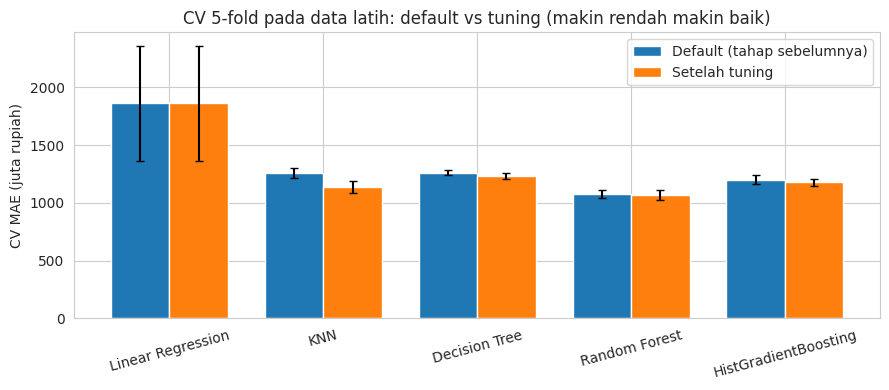

,MAE train (juta),MAE CV (juta),MAE test (juta),rasio test/train
Linear Regression,"1,709.50","1,861.07","1,442.57",0.84
KNN,156.64,"1,135.35","1,087.12",6.94
Decision Tree,982.48,"1,231.55","1,174.16",1.20
Random Forest,480.50,"1,065.38","1,007.41",2.10
HistGradientBoosting,"1,031.50","1,176.88","1,174.81",1.14


,MAE (juta),MAPE (%),R2,Rank MAE,Rank MAPE,Rank R2,Rata-rata rank
Random Forest,"1,007.41",28.32,0.78,1.00,1.00,1.00,1.00
KNN,"1,087.12",29.59,0.75,2.00,2.00,2.00,2.00
Decision Tree,"1,174.16",31.49,0.75,3.00,4.00,3.00,3.33
HistGradientBoosting,"1,174.81",29.85,0.73,4.00,3.00,4.00,3.67
Linear Regression,"1,442.57",37.98,0.57,5.00,5.00,5.00,5.00


Terbaik MAE : Random Forest
Terbaik MAPE: Random Forest
Terbaik R2  : Random Forest


In [39]:
# Ringkasan hasil tuning
# 1) Kandidat RF terbaik + simpangan antar fold: apakah pemenang benar-benar stabil, bukan kebetulan?
h = hasil_cari['Random Forest'].copy()
h.columns = [c.replace('regressor__model__', '') for c in h.columns]
h['CV MAE (juta)'] = -h['mean_test_MAE'] / 1e6
h['std antar fold'] = h['std_test_MAE'] / 1e6
display(h.sort_values('CV MAE (juta)')[['param_max_depth', 'param_min_samples_leaf', 'param_max_features',
                                         'CV MAE (juta)', 'std antar fold']].head(5).round(2))

# 2) Default vs tuning pada CV yang sama (garis error = simpangan antar fold)
nm = list(cv_default)
x, w = np.arange(len(nm)), 0.38
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - w/2, [cv_default[n]['MAE (juta)'] for n in nm], w, yerr=[cv_default[n]['MAE std'] for n in nm],
       capsize=3, label='Default (tahap sebelumnya)')
ax.bar(x + w/2, [cv_pilih[n]['MAE (juta)'] for n in nm], w, yerr=[cv_pilih[n]['MAE std'] for n in nm],
       capsize=3, label='Setelah tuning')
ax.set_xticks(x); ax.set_xticklabels(nm, rotation=15); ax.set_ylabel('CV MAE (juta rupiah)')
ax.set_title('CV 5-fold pada data latih: default vs tuning (makin rendah makin baik)'); ax.legend()
plt.tight_layout(); plt.show()

# 3) Cek overfitting: gap MAE train vs test
gap = pd.DataFrame({
    'MAE train (juta)': {n: evaluasi(y_train, m.predict(X_train[kolom]))['MAE (juta)'] for n, m in model_terlatih.items()},
    'MAE CV (juta)': pd.Series(cv_mae),
    'MAE test (juta)': res_tune['MAE (juta)']})
gap['rasio test/train'] = gap['MAE test (juta)'] / gap['MAE train (juta)']
display(gap.round(2))

# 4) Peringkat per metrik di test set bersih (jawaban untuk poin "model terbaik berdasarkan MAE, MAPE, R2")
peringkat = res_tune[['MAE (juta)', 'MAPE (%)', 'R2']].copy()
peringkat['Rank MAE'] = peringkat['MAE (juta)'].rank()
peringkat['Rank MAPE'] = peringkat['MAPE (%)'].rank()
peringkat['Rank R2'] = peringkat['R2'].rank(ascending=False)
peringkat['Rata-rata rank'] = peringkat[['Rank MAE', 'Rank MAPE', 'Rank R2']].mean(axis=1)
display(peringkat.sort_values('Rata-rata rank').round(2))
print('Terbaik MAE :', res_tune['MAE (juta)'].idxmin())
print('Terbaik MAPE:', res_tune['MAPE (%)'].idxmin())
print('Terbaik R2  :', res_tune['R2'].idxmax())


Semua tahap dalam satu tabel, semuanya diuji di test set yang sama. MAPE dalam persen; MedAPE (median) ditambahkan karena MAPE rata-rata terpengaruh rumah murah.

1_Direct                                                \
                     MAE (juta)  MAPE (%) MedAPE (%)          R2  RMSE (juta)   
Linear Regression    147,559.46 12,857.89   8,323.57     -438.65   155,395.83   
KNN                  270,810.89  1,268.39      20.73 -954,988.12 7,242,473.07   
Decision Tree        160,229.36    736.51      63.80 -591,849.03 5,701,557.60   
Random Forest        164,697.73  1,108.33      18.06 -331,515.11 4,267,170.54   
HistGradientBoosting 160,497.41  8,084.58   5,614.59  -38,286.02 1,450,151.77   

                     2_Preprocessing                                       \
                          MAE (juta) MAPE (%) MedAPE (%)   R2 RMSE (juta)   
Linear Regression           1,385.50    35.42      23.33 0.61    4,644.76   
KNN                         1,262.52    32.82      20.52 0.70    4,061.93   
Decision Tree               1,196.68    34.05      19.03 0.72    3,909.34   
Random Forest               1,022.72    28.87      15.31 0.77    3,523.57   
HistGradientBoosting        1,192.14    29.77      19.53 0.71    3,959.37   

                     3_FeatureSelection                                       \
                             MAE (juta) MAPE (%) MedAPE (%)   R2 RMSE (juta)   
Linear Regression              1,442.57    37.98      24.36 0.57    4,854.45   
KNN                            1,246.82    33.04      19.84 0.71    4,004.09   
Decision Tree                  1,194.38    34.68      18.94 0.73    3,857.02   
Random Forest                  1,020.21    28.80      15.14 0.77    3,528.46   
HistGradientBoosting           1,207.85    30.43      19.60 0.71    3,978.02   

                        4_Tuned                                       
                     MAE (juta) MAPE (%) MedAPE (%)   R2 RMSE (juta)  
Linear Regression      1,442.57    37.98      24.36 0.57    4,854.45  
KNN                    1,087.12    29.59      15.71 0.75    3,720.27  
Decision Tree          1,174.16    31.49      19.09 0.75    3,731.53  
Random Forest          1,007.41    28.32      14.87 0.78    3,490.83  
HistGradientBoosting   1,174.81    29.85      18.55 0.73    3,844.22

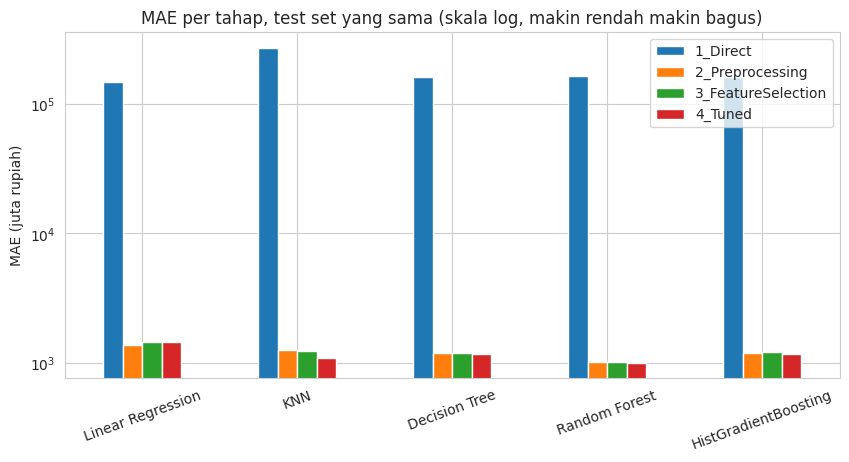

In [40]:
kolom_metrik = ['MAE (juta)', 'RMSE (juta)', 'MAPE (%)', 'MedAPE (%)', 'R2']
semua = pd.concat({
    '1_Direct': res_direct[kolom_metrik],
    '2_Preprocessing': res_prep[kolom_metrik],
    '3_FeatureSelection': res_fs[kolom_metrik],
    '4_Tuned': res_tune[kolom_metrik],
})
display(semua.unstack(0).swaplevel(axis=1).sort_index(axis=1))

semua['MAE (juta)'].unstack(0).plot(kind='bar', figsize=(10, 4.5))
plt.ylabel('MAE (juta rupiah)'); plt.yscale('log')
plt.title('MAE per tahap, test set yang sama (skala log, makin rendah makin bagus)')
plt.xticks(rotation=20)
plt.show()

Model dipilih berdasarkan MAE dari CV 5-fold pada data latih, bukan dari skor test. Setelah pemilihan, model dievaluasi pada test set bersih yang berisi 5.534 baris. Model yang dipakai untuk deployment berasal dari tahap ini.

CV MAE 5-fold seluruh data latih (juta): {'Linear Regression': np.float64(1861.1), 'KNN': np.float64(1135.4), 'Decision Tree': np.float64(1231.5), 'Random Forest': np.float64(1065.4), 'HistGradientBoosting': np.float64(1176.9)}
model terbaik: Random Forest | sumber parameter: hasil tuning
{'max_depth': None, 'max_features': np.float64(0.6592), 'min_samples_leaf': 1}

hasil test set utuh (dilihat setelah model dipilih):
MAE (juta)    1,007.41
RMSE (juta)   3,490.83
MAPE (%)         28.32
MedAPE (%)       14.87
R2                0.78
Name: Random Forest, dtype: object


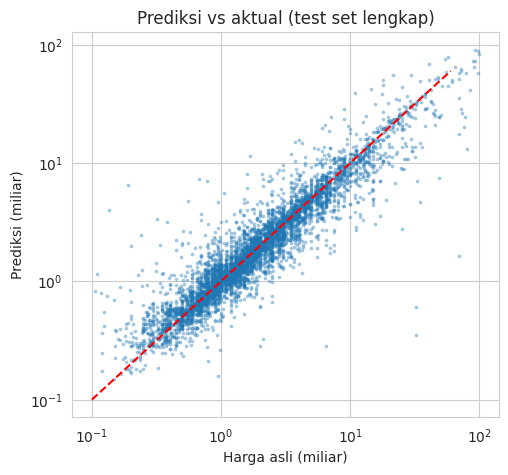

In [41]:
# model terbaik dipilih dari skor CV 5-fold di data train (seluruh baris), BUKAN dari test set
nama_terbaik = min(cv_mae, key=cv_mae.get)
model_final = model_terlatih[nama_terbaik]
cv5_final = cv_mae[nama_terbaik]       # sudah CV 5-fold pada seluruh data latih
n_cv = len(X_train)

print('CV MAE 5-fold seluruh data latih (juta):', {k: round(v, 1) for k, v in cv_mae.items()})
print('model terbaik:', nama_terbaik, '| sumber parameter:', sumber[nama_terbaik])
print({k.replace(pre, ''): (round(v, 4) if isinstance(v, float) else v) for k, v in param_terbaik[nama_terbaik].items()})
print()
print('hasil test set utuh (dilihat setelah model dipilih):')
print(res_tune.loc[nama_terbaik, kolom_metrik])

pred = model_final.predict(X_test[kolom])
plt.figure(figsize=(5.5, 5))
plt.scatter(y_test / 1e9, pred / 1e9, s=3, alpha=0.3)
plt.plot([0.1, 60], [0.1, 60], 'r--')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Harga asli (miliar)'); plt.ylabel('Prediksi (miliar)')
plt.title('Prediksi vs aktual (test set lengkap)')
plt.show()


### Audit galat
Baris dengan galat absolut terbesar ditampilkan untuk mencari pola kesalahan, bukan untuk dihapus dari evaluasi. Metrik resmi tetap dihitung pada seluruh test set. Properti dengan LT besar, LB kosong, harga tinggi, atau lokasi yang jarang muncul bisa memiliki galat lebih besar; temuan ini perlu dibaca sebagai keterbatasan data dan model.

In [42]:
def baris_galat_terbesar(model, n=8):
    pred = model.predict(X_test[kolom])
    tabel = X_test[['KT', 'KM', 'LT', 'LB', 'Kecamatan']].copy()
    tabel['asli (miliar)'] = y_test / 1e9
    tabel['prediksi (miliar)'] = pred / 1e9
    tabel['galat (miliar)'] = np.abs(y_test - pred) / 1e9
    return tabel.sort_values('galat (miliar)', ascending=False).head(n)

print('Model terbaik:', nama_terbaik)
display(baris_galat_terbesar(model_final))
print('Metrik resmi tetap dihitung pada seluruh test set. Tabel di atas hanya dipakai untuk mencari pola galat, bukan untuk menghapus observasi sulit.')


Model terbaik: Random Forest


,KT,KM,LT,LB,Kecamatan,asli (miliar),prediksi (miliar),galat (miliar)
21359,NaN,NaN,NaN,NaN,Sawangan,70.00,1.63,68.37
17742,NaN,NaN,"3,914.00",NaN,Pancoran Mas,80.00,13.07,66.93
20804,NaN,NaN,"3,031.00",NaN,Limo,75.80,20.12,55.68
25985,NaN,NaN,"2,259.00","1,836.00",Pancoran Mas,78.00,24.62,53.38
9233,3.00,9.00,"8,126.00","2,000.00",Beji,69.00,17.56,51.44
13823,NaN,NaN,"6,150.00",NaN,Beji,73.80,26.36,47.44
26964,NaN,NaN,"9,485.00",NaN,Cinere,85.40,41.18,44.22
19911,NaN,NaN,"6,000.00",NaN,Sukmajaya,72.00,28.44,43.56


Metrik resmi tetap dihitung pada seluruh test set. Tabel di atas hanya dipakai untuk mencari pola galat, bukan untuk menghapus observasi sulit.


## 6. Simpan model untuk Deployment
Model terbaik disimpan dalam satu file `model_harga_rumah.joblib` (model, kolom, dan ringkasan metrik). Model final memakai KT, KM, LT, LB, Kecamatan, serta fitur turunan. `Garasi` tidak terpilih pada feature selection, jadi aplikasi tidak menampilkannya sebagai input agar pengguna tidak mengira nilainya ikut memengaruhi prediksi. `requirements.txt` mencatat versi library training supaya artefak lebih mudah direproduksi.

In [43]:
# satu file berisi model dan info yang dibutuhkan app.py
freq_train = X_train['Kecamatan'].value_counts()
kecamatan_app = sorted(freq_train[freq_train >= 80].index.tolist())
paket = {
    'model': model_final,
    'kolom': kolom,
    'nama_model': nama_terbaik,
    'mae_test_rupiah': float(res_tune.loc[nama_terbaik, 'MAE (juta)'] * 1e6),
    'cv_mae_5fold_juta': float(cv5_final),
    'cv5_n': int(n_cv),
    'kecamatan': kecamatan_app,
    'fitur_num': fitur_num,
    'fitur_cat': fitur_cat,
    'random_state': RANDOM_STATE,
    'target_scope_rupiah': [100_000_000, 100_000_000_000],
    'scikit_learn_version': version('scikit-learn'),
}
joblib.dump(paket, 'model_harga_rumah.joblib', compress=3)

# Versi library diambil dari environment training supaya artefak lebih mudah direproduksi.
with open('requirements.txt', 'w') as f:
    f.write('streamlit>=1.32,<2\n')
    for nama in ['scikit-learn', 'pandas', 'numpy', 'joblib']:
        f.write(f'{nama}=={version(nama)}\n')

print('Ukuran model (MB):', round(os.path.getsize('model_harga_rumah.joblib') / 1e6, 2))
print('MAE CV 5-fold seluruh data latih,', paket['cv5_n'], 'baris (juta):', round(paket['cv_mae_5fold_juta'], 2))
print('MAE test (juta):', round(paket['mae_test_rupiah'] / 1e6, 2))
print(open('requirements.txt').read())

Ukuran model (MB): 38.1
MAE CV 5-fold seluruh data latih, 22134 baris (juta): 1065.38
MAE test (juta): 1007.41
streamlit>=1.32,<2
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.1.3
joblib==1.6.0



Tes load ulang dan prediksi dalam kondisi input normal, LB kosong, dan kecamatan yang tidak dikenal. Garasi tidak diuji sebagai faktor prediksi karena fitur tersebut tidak terpilih pada model final.

In [44]:
# tes load ulang dan prediksi, sama seperti yang dilakukan app.py
paket = joblib.load('model_harga_rumah.joblib')

def prediksi(**isi):
    x = buat_fitur(pd.DataFrame([isi]))
    return paket['model'].predict(x[paket['kolom']])[0]

contoh = dict(KT=3, KM=2, Garasi=0, LT=90, LB=70, Kecamatan='Sawangan')
print('Estimasi harga normal   : Rp {:,.0f}'.format(prediksi(**contoh)))
print('Tanpa LB (NaN)          : Rp {:,.0f}'.format(prediksi(**{**contoh, 'LB': np.nan})))
print('Kecamatan tidak dikenal : Rp {:,.0f}'.format(prediksi(**{**contoh, 'Kecamatan': 'Lainnya'})))

Estimasi harga normal   : Rp 978,891,072
Tanpa LB (NaN)          : Rp 344,750,231
Kecamatan tidak dikenal : Rp 941,064,748


## 7. Ringkasan hasil
Sel berikut merangkum hasil dari eksekusi notebook. Jika ada perubahan kode atau data, jalankan ulang notebook dan gunakan angka dari hasil terbaru.

In [45]:
r = res_tune.loc[nama_terbaik]
d0, d1 = res_direct.loc[nama_terbaik], res_prep.loc[nama_terbaik]
print('Imputasi missing value:', IMPUTASI)
print('Model terbaik (dipilih lewat CV 5-fold data latih):', nama_terbaik)
print('Sumber parameter:', sumber[nama_terbaik])
print('CV MAE 5-fold seluruh data latih,', n_cv, 'baris (juta):', round(cv5_final, 1))
print('Jumlah test set utuh:', len(y_test))
print(f"Test set: MAE Rp{r['MAE (juta)']:,.0f} juta | RMSE Rp{r['RMSE (juta)']:,.0f} juta | MAPE {r['MAPE (%)']:.1f}% | MedAPE {r['MedAPE (%)']:.1f}% | R2 {r['R2']:.2f}")
print(f"Model yang sama, direct (data naif): MAE Rp{d0['MAE (juta)']:,.0f} juta | R2 {d0['R2']:.2f}")
print(f"Model yang sama, setelah preprocessing: MAE Rp{d1['MAE (juta)']:,.0f} juta | R2 {d1['R2']:.2f}")
print(f"Median harga test: Rp{y_test.median() / 1e6:,.0f} juta | rata-rata: Rp{y_test.mean() / 1e6:,.0f} juta")

Imputasi missing value: median
Model terbaik (dipilih lewat CV 5-fold data latih): Random Forest
Sumber parameter: hasil tuning
CV MAE 5-fold seluruh data latih, 22134 baris (juta): 1065.4
Jumlah test set utuh: 5534
Test set: MAE Rp1,007 juta | RMSE Rp3,491 juta | MAPE 28.3% | MedAPE 14.9% | R2 0.78
Model yang sama, direct (data naif): MAE Rp164,698 juta | R2 -331515.11
Model yang sama, setelah preprocessing: MAE Rp1,023 juta | R2 0.77
Median harga test: Rp1,600 juta | rata-rata: Rp3,734 juta


### Kesimpulan dan keterbatasan
- Pembersihan data menurunkan error dibanding direct modeling, tetapi perbandingan ini mengukur seluruh paket pembersihan, bukan satu teknik saja.
- Model terbaik dipilih melalui MAE cross-validation pada training data. Hasil test dihitung pada seluruh baris test yang lolos cakupan proyek, tanpa penyaringan harga-per-luas setelah split.
- MAE dan RMSE dalam rupiah besar karena error pada properti bernilai tinggi memiliki pengaruh besar; MedAPE membantu melihat kesalahan relatif rumah yang lebih umum. Tidak ada satu metrik yang menceritakan semuanya.
- Nilai KT/KM/Garasi yang sangat besar dan LT/LB yang ekstrem ditandai sebagai missing pada fitur, bukan langsung menghapus seluruh listing. Batas ini tetap merupakan aturan domain proyek yang perlu ditinjau jika cakupan berubah.
- Harga yang tidak dapat diparsing, harga yang tidak tercantum, harga per luas, serta nilai di luar cakupan Rp100 juta–Rp100 miliar tidak dipakai sebagai target training.
- Tanpa URL/ID listing, deduplikasi semantik masih memakai heuristik; sebagian listing serupa mungkin bukan listing yang sama.
- Pemetaan Kecamatan hanya dilakukan untuk label yang bisa ditelusuri; nama yang ambigu dibiarkan.
- Uji imputasi yang menyembunyikan nilai secara acak hanya pembanding, karena missing value asli kemungkinan tidak acak. Yang menentukan pilihan tetap hasil CV.
- Model masih sulit untuk properti sangat luas, fitur yang banyak kosong, atau lokasi dengan sedikit contoh. Harga yang diprediksi adalah harga penawaran, bukan nilai transaksi maupun appraisal resmi.
- Nilai metrik final harus dibaca dari output eksekusi terakhir, karena perubahan kebijakan data dapat mengubah MAE, RMSE, MAPE, dan R².


### Catatan penutup
Pencarian parameter memakai CV 5-fold pada seluruh data latih, dan metrik test dihitung satu kali pada seluruh test set. Batas cakupan harga, aturan pembersihan, ketiadaan ID listing, perbedaan garasi nol dan missing, serta dampak lokasi yang tidak merata perlu dijelaskan saat presentasi. Skor model adalah estimasi harga penawaran, bukan appraisal resmi.